# 04 - Scaffold split and uncertainty (ESOL)

CHE1147 Final Project, Team 9. In `02_baselines.ipynb` and `03_models.ipynb` every model was tested on 10 stratified random 80/20 splits. In a random split, very similar molecules (for example two isomers of dichlorobenzene) often end up on both sides, and about 50 of the 223 test molecules have a "descriptor twin" in the training set that kNN can copy.

Section 4 of our proposal planned "a scaffold split, with each ring scaffold wholly in the training or the test set", to "check whether kNN benefited from near-identical molecules". The feedback on the proposal asked us to make this a main result. In this notebook we:

1. build 10 scaffold splits, in which every test molecule has a scaffold (its ring systems and the linkers between them) that is not in the training set (a group split, Lecture 3, slide 17)
2. train and test all models on them and compare with the random splits
3. look at how the error depends on how similar a test molecule is to the training set (Tanimoto similarity, Tutorial 3)
4. estimate the uncertainty of each prediction from the spread of the random forest's trees (the tree standard deviation, Lecture 9) and check whether it tells us which predictions to trust, and compare it with a Gaussian process (section 8.1)

We made these choices before running anything (in our written plan for this notebook). The success rule of the research question stays on the random splits.
- Scaffold split: the "balanced" split of Yang et al. (2019), described in section 2.
- Models: the baselines of `02_baselines.ipynb` and the three models of `03_models.ipynb` with the feature set that cross-validation chose in all 10 random splits (descriptors + fingerprints), tuned in the same way. One extra check is XGBoost on the 9 descriptors only, to see whether the fingerprints still help on new scaffolds. Ridge with descriptors + fingerprints was added later as a linear control, as in `03_models.ipynb`.
- Similarity bins (below 0.3, 0.3 to 0.5, 0.5 to 0.7, and 0.7 or more) and 5 equal uncertainty groups.
- What we expected: all models get worse on the scaffold splits, kNN loses most of its twin advantage, and the gap between XGBoost and kNN stays the same or grows.

Outline:

0. Setup
1. Data, fingerprints and scaffolds
2. Scaffold splits
3. Models on the scaffold splits
4. Random forest on the random splits (for the uncertainty)
5. Results: random vs. scaffold splits
6. A fair comparison: the same molecules
7. Error and similarity to the training set
8. Uncertainty from the random forest
9. Figures

Abbreviations used in this notebook: GP (Gaussian process), KRR (kernel ridge regression), kNN (k-nearest neighbours), MAE (mean absolute error), PAH (polycyclic aromatic hydrocarbon), PCB (polychlorinated biphenyl), RBF (radial basis function), RMSE (root mean squared error), SD (standard deviation), SHAP (SHapley Additive exPlanations).

## 0. Setup

In [1]:
# Source: import blocks of Tutorial 4 (0.2) and Tutorial 5 (0.2), as in 03_models.ipynb
# Changes: DummyRegressor, LinearRegression, KFold (Tutorial 4 (11.1)), Tanimoto tools (Tutorial 3 (4.))

# basics
import os
import sys
import ast   # not in the tutorials: reads the settings saved as text in notebook 03
import time
import numpy as np
import pandas as pd

# chemistry
from rdkit import DataStructs
from rdkit.Chem import rdFingerprintGenerator

# machine learning dependencies
from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold, GridSearchCV, RandomizedSearchCV, GroupShuffleSplit
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score   # imported as in Tutorial 9. Tutorial 4 (3.1) has the MAE and MSE
from sklearn.gaussian_process import GaussianProcessRegressor   # Lecture 10 (slides 9 to 12)
from sklearn.gaussian_process.kernels import RBF

# plotting
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D   # legend entries drawn by hand (not in the tutorials)
from matplotlib.colors import LogNorm   # log colour scale for the parity plot, as in Tutorial 4 (6.)
%matplotlib inline

# our shared functions in src/ (imported like MOF_descriptors.py in Tutorial 4)
sys.path.append(os.path.join('..', 'src'))
from esol_data import (RANDOM_SEED, TARGET, DELANEY, FEATURES, FEATURES_9, ESOL_TERMS, FP_COLUMNS,
                       FP_RADIUS, FP_SIZE, prepare_esol, morgan_fingerprints, stratified_split,
                       murcko_scaffolds, scaffold_split)
from esol_evaluation import regression_metrics, set_paper_style, MODEL_COLOURS, FULL_WIDTH

set_paper_style()

In [2]:
# Source: Tutorial 4 (0.3 Fix the random seed). RANDOM_SEED = 1 is defined in src/esol_data.py
np.random.seed(RANDOM_SEED)

FIG_DIR = os.path.join('..', 'results', 'figures')
TABLE_DIR = os.path.join('..', 'results', 'tables')
os.makedirs(FIG_DIR, exist_ok=True)

# the random-split results of 02_baselines.ipynb and 03_models.ipynb are needed for the comparison
for file_name in ['baselines_per_split.csv', 'baselines_test_predictions.csv',
                  'models_all_results.csv', 'models_test_predictions.csv']:
    if not os.path.exists(os.path.join(TABLE_DIR, file_name)):
        raise FileNotFoundError(f"results/tables/{file_name} is missing: run 02_baselines.ipynb and "
                                "03_models.ipynb first")

SPLIT_SEEDS = range(1, 11)   # 10 splits of each kind, as in notebooks 02 and 03
N_ITER = 20                  # random settings tried per model, as in 03_models.ipynb
N_JOBS = -1                  # all CPU cores

## 1. Data, fingerprints and scaffolds

The Bemis-Murcko scaffold of a molecule is what is left when all side chains are removed, that is, its ring systems and the chains that link them (Bemis and Murcko, 1996). All substituted benzenes have the scaffold "benzene", and molecules without a ring (for example alkanes and alcohols) have an empty scaffold.

In [3]:
# Source: prepare_esol(), morgan_fingerprints() and murcko_scaffolds() in src/esol_data.py
df_clean = prepare_esol()
fingerprint_df = morgan_fingerprints(df_clean)
df_model = pd.concat([df_clean, fingerprint_df], axis=1)
scaffolds = murcko_scaffolds(df_clean)

group_sizes = scaffolds.value_counts()
print(f"Molecules without a ring (empty scaffold): {(scaffolds == '').sum()}")
print(f"Different ring scaffolds: {(group_sizes.index != '').sum()}")
print("\nLargest scaffold groups (number of molecules):")
print(group_sizes.head(8).rename(index={'': '(no ring)'}).to_string())

Loaded data/delaney-processed.csv, shape = (1128, 10)


Dataset size: 1128 rows, 1115 unique molecules


Molecules without a ring (empty scaffold): 314
Different ring scaffolds: 268

Largest scaffold groups (number of molecules):
scaffold
(no ring)                       314
c1ccccc1                        253
c1ccc(-c2ccccc2)cc1              39
c1ccc2ccccc2c1                   21
O=C1CC(=O)NC(=O)N1               19
O=C1C=C2CCC3C4CCCC4CCC3C2CC1     17
c1ncncn1                         16
c1ccncc1                         14


In [4]:
# Source: Tutorial 3 (4. Molecular Fingerprints & Similarity: fingerprint generator, TanimotoSimilarity)
# Changes: BulkTanimotoSimilarity (same values as TanimotoSimilarity, one fingerprint against a list)
# same fingerprints as the model features (radius 2, 2,048 bits)
morgan_gen = rdFingerprintGenerator.GetMorganGenerator(radius=FP_RADIUS, fpSize=FP_SIZE)
fp_vectors = {}
for i, mol in df_clean['molecule'].items():
    fp_vectors[i] = morgan_gen.GetFingerprint(mol)


def max_similarity_to_training(df_train, df_test):
    """For each test molecule, the highest Tanimoto similarity to any molecule of the training set."""
    train_fps = [fp_vectors[i] for i in df_train.index]
    max_similarity = []
    for i in df_test.index:
        max_similarity.append(max(DataStructs.BulkTanimotoSimilarity(fp_vectors[i], train_fps)))
    return pd.Series(max_similarity, index=df_test.index)


# Source: twin check of 02_baselines.ipynb (section 5): 8 descriptors rounded to 6 decimals
def has_twin(df_train, df_test):
    """True for test molecules whose 8 descriptors match a training molecule (a descriptor twin)."""
    train_descriptors = set()
    for row in df_train[FEATURES].round(6).values:
        train_descriptors.add(tuple(row))
    twins = []
    for row in df_test[FEATURES].round(6).values:
        twins.append(tuple(row) in train_descriptors)
    return pd.Series(twins, index=df_test.index)


# Source: new (final project)
def scaffold_category(df_train, df_test):
    """Kind of each test molecule: no ring, benzene, or another ring scaffold that is / is not in training."""
    train_scaffolds = set(scaffolds[df_train.index])
    categories = []
    for i in df_test.index:
        if scaffolds[i] == '':
            categories.append('no ring')
        elif scaffolds[i] == 'c1ccccc1':
            categories.append('benzene')
        elif scaffolds[i] in train_scaffolds:
            categories.append('other ring, in training')
        else:
            categories.append('other ring, not in training')
    return pd.Series(categories, index=df_test.index)

## 2. Scaffold splits

Why not use scikit-learn's `GroupShuffleSplit`? It puts 20% of the groups in the test set, not 20% of the molecules. Our groups have very different sizes (253 substituted benzenes, 314 molecules without a ring and many scaffolds with only one molecule), so the test sets would have very different sizes:

In [5]:
# Source: new (final project). Scikit-learn's GroupShuffleSplit, shown only to explain the choice below
group_shuffle = GroupShuffleSplit(n_splits=10, test_size=0.2, random_state=RANDOM_SEED)
test_sizes = []
for train_index, test_index in group_shuffle.split(df_clean, groups=scaffolds):
    test_sizes.append(len(test_index))
print(f"GroupShuffleSplit test-set sizes: {test_sizes} (random 80/20 split: 223)")

GroupShuffleSplit test-set sizes: [81, 403, 120, 91, 122, 655, 122, 122, 145, 95] (random 80/20 split: 223)


We use a split adapted from the "balanced" scaffold split of Yang et al. (2019) and their Chemprop code instead (`scaffold_split()` in `src/esol_data.py`). The rule for the large groups is the same. We fill the test set first, so that every scaffold test set has 223 molecules, as in the random splits:

1. Scaffold groups larger than half the test set (more than 111 molecules) always go to the training set. Here these are the benzene group (253) and the group of molecules without a ring (314).
2. The other scaffold groups are put in a random order (set by the seed) and added to the test set if they still fit, until it holds 223 molecules, as in the random splits.
3. The rows are shuffled, as `train_test_split` does, because `df_clean` is sorted by SMILES.

Every test molecule then has a scaffold that the model has never seen. Its single rings can still be known: a biphenyl has a new scaffold when no biphenyl is in the training set, even though benzene is. The downside is that substituted benzenes and molecules without a ring are never in a scaffold test set, so for them we use the random splits (section 6). We chose this rule from the group sizes only, before training any model.

For every split we also record how hard the test set is: its log S values (the scaffold splits are not stratified), the number of descriptor twins, and how similar the test molecules are to the training set.

In [6]:
# Source: new (final project). The same facts for the random splits of notebooks 02 and 03 and the scaffold splits
split_facts = []     # one row per split
test_info = []       # one table per split: one row per test molecule
for split_type in ['random', 'scaffold']:
    for seed in SPLIT_SEEDS:
        if split_type == 'random':
            df_train, df_test = stratified_split(df_model, seed)
        else:
            df_train, df_test = scaffold_split(df_model, scaffolds, seed)
        # one row per test molecule: kind of scaffold, twin and highest similarity to the training set
        info = pd.DataFrame({
            'split': split_type, 'seed': seed,
            'category': scaffold_category(df_train, df_test),
            'twin': has_twin(df_train, df_test),
            'max_similarity': max_similarity_to_training(df_train, df_test),
        })
        test_info.append(info)
        # one row for the whole split
        split_facts.append({
            'split': split_type, 'seed': seed, 'n_train': len(df_train), 'n_test': len(df_test),
            'test_logS_mean': df_test[TARGET].mean(), 'test_logS_sd': df_test[TARGET].std(),
            'n_twins': info['twin'].sum(),
            'median_max_similarity': info['max_similarity'].median(),
            'share_similarity_0.7_or_more': (info['max_similarity'] >= 0.7).mean(),
        })

# put the splits together and save the facts
test_info = pd.concat(test_info)
test_info.index.name = 'molecule'
split_facts = pd.DataFrame(split_facts)
split_facts.round(3).to_csv(os.path.join(TABLE_DIR, 'scaffold_split_facts.csv'), index=False)

# the scaffold test sets only contain other ring scaffolds that are not in training
scaffold_categories = test_info[test_info['split'] == 'scaffold']['category']
assert (scaffold_categories == 'other ring, not in training').all()

# smallest and largest value of each fact over the 10 splits of each kind
fact_columns = ['n_test', 'test_logS_mean', 'test_logS_sd', 'n_twins',
                'median_max_similarity', 'share_similarity_0.7_or_more']
fact_ranges = split_facts.groupby('split')[fact_columns].agg(['min', 'max'])
print(fact_ranges.round(2).T)

split                             random  scaffold
n_test                       min  223.00    223.00
                             max  223.00    223.00
test_logS_mean               min   -3.14     -4.32
                             max   -3.01     -3.23
test_logS_sd                 min    2.06      1.81
                             max    2.23      2.49
n_twins                      min   42.00      6.00
                             max   55.00     12.00
median_max_similarity        min    0.53      0.37
                             max    0.57      0.46
share_similarity_0.7_or_more min    0.18      0.06
                             max    0.26      0.10


In [7]:
# Source: new (final project). The molecules that can be in a scaffold test set
can_be_tested = scaffolds.map(group_sizes) <= 223 / 2
tested_once = test_info[test_info['split'] == 'scaffold'].index.unique()
print(f"Molecules that can be in a scaffold test set: {can_be_tested.sum()} of {len(df_clean)} "
      f"(scaffold neither benzene nor empty)")
print(f"Molecules in at least one of the 10 scaffold test sets: {len(tested_once)}")
print(f"Mean log S of these molecules: {df_clean.loc[can_be_tested, TARGET].mean():.2f} "
      f"(all molecules: {df_clean[TARGET].mean():.2f})")

Molecules that can be in a scaffold test set: 548 of 1115 (scaffold neither benzene nor empty)
Molecules in at least one of the 10 scaffold test sets: 548
Mean log S of these molecules: -3.79 (all molecules: -3.05)


**Observations (scaffold splits)**
- `GroupShuffleSplit` would give test sets of 81 to 655 molecules. With the balanced split, all 10 scaffold test sets have 223 molecules, as in the random splits.
- The scaffold test sets are less similar to the training set. The median maximum Tanimoto similarity is 0.37 to 0.46 (random splits: 0.53 to 0.57), only 6 to 10% of the test molecules have a training molecule with a similarity of 0.7 or more (random: 18 to 26%), and there are only 6 to 12 descriptor twins per test set (random: 42 to 55). They are harder but not completely new, since a few test molecules still have a close relative in the training set.
- The scaffold test sets are less soluble on average and vary more from split to split, with a mean log S of -4.32 to -3.23 (random: -3.14 to -3.01) and a standard deviation of 1.81 to 2.49 (random: 2.06 to 2.23). The 548 molecules that can be in a scaffold test set have a mean log S of -3.79, against -3.05 for all molecules. Every one of them is in at least one of the 10 scaffold test sets.

## 3. Models on the scaffold splits

We use the same models as before, built by the same functions in `src/esol_models.py` (as in `02_baselines.ipynb` and `03_models.ipynb`):
- baselines: the mean predictor, the ESOL equation (Delaney's published predictions, which are in-sample because Delaney fitted the equation on these molecules), the ESOL equation refitted with RDKit's Crippen logP, and ridge regression and kNN on the 8 descriptors
- ridge on descriptors + fingerprints, the linear check of `03_models.ipynb`
- kernel ridge, random forest and XGBoost on descriptors + fingerprints, with the same parameter ranges and the same budget (20 random settings)
- XGBoost on the 9 descriptors only, as an extra check

As in Tutorial 4 (11.1), we make the 5 cross-validation folds once per split with `KFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)` and use the same folds for every model. The folds are random and not grouped by scaffold, so the tuning works in the same way as on the random splits (there, `cv=5` cuts training rows that `train_test_split` has already shuffled) and only the test set changes. This makes the cross-validation scores optimistic for new scaffolds, so we only use them to choose the settings and never as results. `05_interpretation.ipynb` (section 4.4) repeats the tuning with folds grouped by scaffold, to check whether this choice changes our results.

In [8]:
# Source: the builder functions of 02_baselines.ipynb and 03_models.ipynb, in src/esol_models.py
#         (Tutorial 4: 4.1, 7.1, 9.1, 11.1)
from esol_models import (make_preprocessing, make_ridge_pipeline, make_knn_pipeline, make_krr_pipeline,
                         make_rf_pipeline, make_xgb_pipeline)

In [9]:
# Source: the parameter ranges of 02_baselines.ipynb and 03_models.ipynb, in src/esol_models.py
from esol_models import ridge_param_grid, knn_param_grid, krr_param_grid, rf_param_grid, xgb_param_grid

DESCRIPTORS_AND_FP = FEATURES_9 + FP_COLUMNS
# model name: (builder, parameter ranges, feature set, columns)
SEARCH_MODELS = {
    'Kernel ridge': (make_krr_pipeline, krr_param_grid, 'descriptors + fingerprints', DESCRIPTORS_AND_FP),
    'Random forest': (make_rf_pipeline, rf_param_grid, 'descriptors + fingerprints', DESCRIPTORS_AND_FP),
    'XGBoost': (make_xgb_pipeline, xgb_param_grid, 'descriptors + fingerprints', DESCRIPTORS_AND_FP),
    'XGBoost (9 descriptors)': (make_xgb_pipeline, xgb_param_grid, '9 descriptors', FEATURES_9),
}

In [10]:
# Source: new (final project). Predictions of every tree of a random forest (Lecture 9, slides 19 and 22)
def tree_spread(forest_pipeline, X):
    """Mean and standard deviation of the predictions of the individual trees of a fitted forest pipeline."""
    X_prepared = forest_pipeline.named_steps['preprocessing'].transform(X)
    forest = forest_pipeline.named_steps['forest']
    tree_predictions = []
    for tree in forest.estimators_:
        tree_predictions.append(tree.predict(X_prepared))
    tree_predictions = np.array(tree_predictions)   # one row per tree, one column per molecule
    return tree_predictions.mean(axis=0), tree_predictions.std(axis=0)

For each scaffold split we tune on the training set (5-fold cross-validation), predict the test set, and keep the spread of the random forest's trees for section 8. This takes about 20 minutes.

In [11]:
# Source: the 10-split loops of 02_baselines.ipynb (run_baselines) and 03_models.ipynb
# Changes: scaffold splits. One fixed set of shuffled 5-fold folds per split (Tutorial 4 (11.1))
scaffold_predictions = []   # test-set predictions, one table per split and model
scaffold_settings = []      # settings chosen by cross-validation
scaffold_spread = []        # standard deviation of the random forest's trees, per test molecule

for seed in SPLIT_SEEDS:
    start = time.time()
    df_train, df_test = scaffold_split(df_model, scaffolds, seed)
    y_train = df_train[TARGET]
    cv_folds = list(KFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED).split(df_train))
    predictions = {}

    # baselines, as in 02_baselines.ipynb
    mean_predictor = DummyRegressor(strategy='mean').fit(df_train[FEATURES], y_train)
    predictions['Mean predictor'] = mean_predictor.predict(df_test[FEATURES])
    predictions['ESOL equation (Delaney, 2004)'] = df_test[DELANEY].values
    esol_refit = LinearRegression().fit(df_train[ESOL_TERMS], y_train)
    predictions['ESOL refit (Crippen logP)'] = esol_refit.predict(df_test[ESOL_TERMS])
    for model_name, make_model, param_grid in [('Ridge (8 descriptors)', make_ridge_pipeline, ridge_param_grid),
                                              ('kNN (8 descriptors)', make_knn_pipeline, knn_param_grid)]:
        search = GridSearchCV(make_model(), param_grid=param_grid, cv=cv_folds,
                              scoring='neg_mean_absolute_error', n_jobs=N_JOBS)
        search.fit(df_train[FEATURES], y_train)
        predictions[model_name] = search.predict(df_test[FEATURES])
        scaffold_settings.append({'seed': seed, 'model': model_name, 'best_params': search.best_params_})

    # ridge with the same features as the models (the linear check of 03_models.ipynb)
    search = GridSearchCV(make_ridge_pipeline('descriptors + fingerprints'), param_grid=ridge_param_grid,
                          cv=cv_folds, scoring='neg_mean_absolute_error', n_jobs=N_JOBS)
    search.fit(df_train[DESCRIPTORS_AND_FP], y_train)
    predictions['Ridge (descriptors + fingerprints)'] = search.predict(df_test[DESCRIPTORS_AND_FP])
    scaffold_settings.append({'seed': seed, 'model': 'Ridge (descriptors + fingerprints)',
                              'best_params': search.best_params_})

    # the models of 03_models.ipynb
    for model_name, (make_model, param_grid, feature_set, columns) in SEARCH_MODELS.items():
        search = RandomizedSearchCV(make_model(feature_set), param_distributions=param_grid, n_iter=N_ITER,
                                    cv=cv_folds, scoring='neg_mean_absolute_error',
                                    random_state=RANDOM_SEED, n_jobs=N_JOBS)
        search.fit(df_train[columns], y_train)
        predictions[model_name] = search.predict(df_test[columns])
        scaffold_settings.append({'seed': seed, 'model': model_name, 'best_params': search.best_params_})

        if model_name == 'Random forest':
            tree_mean, tree_sd = tree_spread(search.best_estimator_, df_test[columns])
            assert np.allclose(tree_mean, predictions[model_name])   # the forest predicts the mean of its trees
            scaffold_spread.append(pd.DataFrame({'split': 'scaffold', 'seed': seed, 'tree_sd': tree_sd},
                                              index=df_test.index))

    for model_name, y_pred in predictions.items():
        scaffold_predictions.append(pd.DataFrame({'split': 'scaffold', 'seed': seed, 'model': model_name,
                                                  'y_true': df_test[TARGET], 'y_pred': y_pred}))
    print(f"scaffold split {seed}: done in {time.time() - start:.0f} s")

scaffold_predictions = pd.concat(scaffold_predictions)
scaffold_predictions.index.name = 'molecule'
scaffold_settings = pd.DataFrame(scaffold_settings)
scaffold_settings.to_csv(os.path.join(TABLE_DIR, 'scaffold_settings.csv'), index=False)

scaffold split 1: done in 142 s


scaffold split 2: done in 120 s


scaffold split 3: done in 115 s


scaffold split 4: done in 121 s


scaffold split 5: done in 123 s


scaffold split 6: done in 139 s


scaffold split 7: done in 106 s


scaffold split 8: done in 104 s


scaffold split 9: done in 109 s


scaffold split 10: done in 127 s


## 4. Random forest on the random splits (for the uncertainty)

For the uncertainty we also need the spread of the trees on the random splits. We refit the random forest of `03_models.ipynb` (descriptors + fingerprints) on each random split with the settings that cross-validation chose there, and check that it gives exactly the same predictions as in notebook 03.

In [12]:
# Source: new (final project). Settings from results/tables/models_all_results.csv (03_models.ipynb)
results_03 = pd.read_csv(os.path.join(TABLE_DIR, 'models_all_results.csv'))
predictions_03 = pd.read_csv(os.path.join(TABLE_DIR, 'models_test_predictions.csv'), index_col=0)

random_spread = []   # tree standard deviation on the random splits (the scaffold ones are from section 3)
for seed in SPLIT_SEEDS:
    df_train, df_test = stratified_split(df_model, seed)
    row = results_03[(results_03['seed'] == seed) & (results_03['model'] == 'Random forest')
                     & (results_03['feature_set'] == 'descriptors + fingerprints')].iloc[0]
    forest = make_rf_pipeline('descriptors + fingerprints')
    # settings saved as text, ast.literal_eval turns them back into a dictionary
    forest.set_params(**ast.literal_eval(row['best_params']))
    forest.fit(df_train[DESCRIPTORS_AND_FP], df_train[TARGET])

    tree_mean, tree_sd = tree_spread(forest, df_test[DESCRIPTORS_AND_FP])
    saved = predictions_03[(predictions_03['seed'] == seed) & (predictions_03['model'] == 'Random forest')
                           & (predictions_03['feature_set'] == 'descriptors + fingerprints')]
    assert np.allclose(tree_mean, saved.loc[df_test.index, 'y_pred'])   # same predictions as in notebook 03
    random_spread.append(pd.DataFrame({'split': 'random', 'seed': seed, 'tree_sd': tree_sd}, index=df_test.index))

forest_spread = pd.concat(scaffold_spread + random_spread)   # scaffold first, as before
forest_spread.index.name = 'molecule'
print("The refitted random forests give the same test predictions as in 03_models.ipynb in all 10 random splits")

The refitted random forests give the same test predictions as in 03_models.ipynb in all 10 random splits


## 5. Results: random vs. scaffold splits

The random-split predictions come from `02_baselines.ipynb` and `03_models.ipynb` (same models, same settings), and we compute the metrics of both kinds of split from the saved test-set predictions in the same way. The 10 scaffold test sets share many molecules (2,230 predictions of only 548 different molecules, section 9), even more than the random ones, so the SD and the "N of 10" counts are summaries of the splits, not a statistical test.

In [13]:
# Source: new (final project). Test-set predictions of notebooks 02 and 03 in the same format as above
# the random-split predictions of the baselines (notebook 02)
baseline_predictions = pd.read_csv(os.path.join(TABLE_DIR, 'baselines_test_predictions.csv'), index_col=0)
random_predictions = [baseline_predictions[baseline_predictions['model'].isin(
    ['Mean predictor', 'ESOL equation (Delaney, 2004)', 'ESOL refit (Crippen logP)',
     'Ridge (8 descriptors)', 'kNN (8 descriptors)'])]]
# the three proposed models with descriptors + fingerprints (notebook 03)
for model_name in ['Kernel ridge', 'Random forest', 'XGBoost']:
    rows = predictions_03[(predictions_03['model'] == model_name)
                          & (predictions_03['feature_set'] == 'descriptors + fingerprints')]
    random_predictions.append(rows)
# two more models of notebook 03: XGBoost without fingerprints and ridge with them
rows = predictions_03[(predictions_03['model'] == 'XGBoost') & (predictions_03['feature_set'] == '9 descriptors')]
random_predictions.append(rows.assign(model='XGBoost (9 descriptors)'))
rows = predictions_03[(predictions_03['model'] == 'Ridge')
                      & (predictions_03['feature_set'] == 'descriptors + fingerprints')]
random_predictions.append(rows.assign(model='Ridge (descriptors + fingerprints)'))

# random and scaffold predictions in one table, with the error of each prediction
random_predictions = pd.concat(random_predictions)[['seed', 'model', 'y_true', 'y_pred']].assign(split='random')
random_predictions.index.name = 'molecule'
all_predictions = pd.concat([random_predictions, scaffold_predictions])
all_predictions['error'] = all_predictions['y_pred'] - all_predictions['y_true']

# add what we know about each test molecule (kind of scaffold, twin, similarity to training)
# pandas merge (not in the tutorials): joins the rows with the same split, seed and molecule
all_predictions = all_predictions.reset_index().merge(test_info.reset_index(), on=['split', 'seed', 'molecule'])
all_predictions.to_csv(os.path.join(TABLE_DIR, 'scaffold_test_predictions.csv'), index=False)

In [14]:
# Source: regression_metrics() from Tutorial 4 (3.1), loop over the splits and models as in 02_baselines.ipynb
per_split = []
for split_type in ['random', 'scaffold']:
    for seed in SPLIT_SEEDS:
        split_rows = all_predictions[(all_predictions['split'] == split_type) & (all_predictions['seed'] == seed)]
        # RMSE of kNN (8 descriptors) on this split, the benchmark
        knn_rows = split_rows[split_rows['model'] == 'kNN (8 descriptors)']
        knn_rmse = regression_metrics(knn_rows['y_true'], knn_rows['y_pred'])['rmse']
        for model_name in sorted(split_rows['model'].unique()):   # models in alphabetical order
            rows = split_rows[split_rows['model'] == model_name]
            metrics = regression_metrics(rows['y_true'], rows['y_pred'])
            metrics.update({'split': split_type, 'seed': seed, 'model': model_name, 'knn_rmse': knn_rmse})
            per_split.append(metrics)
per_split = pd.DataFrame(per_split)

# check: the random-split RMSEs are the same as in notebooks 02 and 03
baselines_02 = pd.read_csv(os.path.join(TABLE_DIR, 'baselines_per_split.csv'))
knn_02 = baselines_02[baselines_02['model'] == 'kNN (8 descriptors)'].set_index('seed')['rmse']
knn_here = per_split[(per_split['split'] == 'random')
                     & (per_split['model'] == 'kNN (8 descriptors)')].set_index('seed')['rmse']
assert np.allclose(knn_02.loc[knn_here.index], knn_here)

# paired comparison with kNN on the same split (negative = better than kNN)
per_split['diff_vs_knn'] = per_split['rmse'] - per_split['knn_rmse']
per_split['win'] = per_split['diff_vs_knn'] < 0   # ties count as losses
per_split.to_csv(os.path.join(TABLE_DIR, 'scaffold_per_split.csv'), index=False)

In [15]:
# Source: summary over the 10 splits as in 02_baselines.ipynb (section 4), written as a loop over the models
# the order of the models in the tables
model_order = ['Mean predictor', 'ESOL equation (Delaney, 2004)', 'ESOL refit (Crippen logP)', 'Ridge (8 descriptors)',
               'kNN (8 descriptors)', 'Ridge (descriptors + fingerprints)', 'Kernel ridge', 'Random forest', 'XGBoost',
               'XGBoost (9 descriptors)']


def summarize(split_type):
    """Mean and standard deviation over the 10 splits of one kind, one row per model."""
    table_rows = []
    # one row per model: mean and SD of the RMSE over the splits, and the comparison with kNN
    for model_name in model_order:
        rows = per_split[(per_split['split'] == split_type) & (per_split['model'] == model_name)]
        table_rows.append({
            'model': model_name,
            'rmse_mean': rows['rmse'].mean(), 'rmse_sd': rows['rmse'].std(),
            'mae_mean': rows['mae'].mean(), 'r2_mean': rows['r2'].mean(),
            'diff_vs_knn_mean': rows['diff_vs_knn'].mean(), 'diff_vs_knn_sd': rows['diff_vs_knn'].std(),
            'wins_vs_knn': rows['win'].sum(),
        })
    table = pd.DataFrame(table_rows).set_index('model')
    table.loc['kNN (8 descriptors)', ['diff_vs_knn_mean', 'diff_vs_knn_sd', 'wins_vs_knn']] = np.nan   # the benchmark
    return table


# summaries of the random and the scaffold splits, saved as CSV
random_summary = summarize('random')
scaffold_summary = summarize('scaffold')
random_summary.round(3).to_csv(os.path.join(TABLE_DIR, 'scaffold_summary_random_splits.csv'))
scaffold_summary.round(3).to_csv(os.path.join(TABLE_DIR, 'scaffold_summary.csv'))

# the main columns (the two CSV files have all columns, with the MAE)
main_columns = pd.DataFrame({
    'RMSE random': random_summary['rmse_mean'],
    'RMSE scaffold': scaffold_summary['rmse_mean'],
    'SD scaffold': scaffold_summary['rmse_sd'],
    # difference of the means, since split i has different molecules in the two kinds
    'scaffold - random': scaffold_summary['rmse_mean'] - random_summary['rmse_mean'],
    'R² scaffold': scaffold_summary['r2_mean'],
    'RMSE - kNN, random': random_summary['diff_vs_knn_mean'],
    'RMSE - kNN, scaffold': scaffold_summary['diff_vs_knn_mean'],
    'SD of difference, scaffold': scaffold_summary['diff_vs_knn_sd'],
    'wins vs kNN, random': random_summary['wins_vs_knn'],
    'wins vs kNN, scaffold': scaffold_summary['wins_vs_knn'],
})
print("ESOL equation: in-sample (Delaney fitted it on these molecules)")
main_columns.round(3)

ESOL equation: in-sample (Delaney fitted it on these molecules)


,RMSE random,RMSE scaffold,SD scaffold,scaffold - random,R² scaffold,"RMSE - kNN, random","RMSE - kNN, scaffold","SD of difference, scaffold","wins vs kNN, random","wins vs kNN, scaffold"
model,,,,,,,,,,
Mean predictor,2.132,2.326,0.291,0.193,-0.191,1.330,1.296,0.260,0.0,0.0
"ESOL equation (Delaney, 2004)",0.929,1.018,0.083,0.089,0.766,0.126,-0.012,0.080,0.0,6.0
ESOL refit (Crippen logP),1.052,1.132,0.067,0.080,0.709,0.249,0.102,0.088,0.0,1.0
Ridge (8 descriptors),1.003,1.080,0.074,0.076,0.734,0.200,0.050,0.092,0.0,2.0
kNN (8 descriptors),0.803,1.030,0.057,0.227,0.763,NaN,NaN,NaN,NaN,NaN
Ridge (descriptors + fingerprints),0.790,0.972,0.062,0.183,0.787,-0.013,-0.058,0.069,7.0,8.0
Kernel ridge,0.654,0.962,0.096,0.308,0.795,-0.149,-0.068,0.057,10.0,9.0
Random forest,0.667,0.870,0.074,0.204,0.832,-0.136,-0.159,0.036,10.0,10.0
XGBoost,0.607,0.834,0.051,0.227,0.844,-0.196,-0.196,0.044,10.0,10.0


In [16]:
# Source: new (final project). The two comparisons decided before the run
# pivot (as in notebook 02): one row per split (seed), one column per model
scaffold_rmse = per_split[per_split['split'] == 'scaffold'].pivot(index='seed', columns='model', values='rmse')
random_rmse = per_split[per_split['split'] == 'random'].pivot(index='seed', columns='model', values='rmse')

# XGBoost against kNN in each split
for name, table in [('Random', random_rmse), ('Scaffold', scaffold_rmse)]:
    d = table['XGBoost'] - table['kNN (8 descriptors)']
    relative = 1 - table['XGBoost'].mean() / table['kNN (8 descriptors)'].mean()
    print(f"{name} splits, XGBoost - kNN (8 descriptors): {d.mean():.3f} ± {d.std():.3f}, "
          f"XGBoost lower in {(d < 0).sum()} of {len(d)} splits, mean RMSE {relative:.0%} lower than kNN")

# XGBoost against ridge on the same inputs (descriptors + fingerprints)
for name, table in [('Random', random_rmse), ('Scaffold', scaffold_rmse)]:
    d = table['XGBoost'] - table['Ridge (descriptors + fingerprints)']
    print(f"{name} splits, XGBoost - ridge with descriptors + fingerprints: {d.mean():.3f} ± {d.std():.3f}, "
          f"XGBoost lower in {(d < 0).sum()} of {len(d)} splits")

# XGBoost with and without the fingerprints
for name, table in [('Random', random_rmse), ('Scaffold', scaffold_rmse)]:
    d = table['XGBoost'] - table['XGBoost (9 descriptors)']
    print(f"{name} splits, XGBoost with fingerprints - without: {d.mean():.3f} ± {d.std():.3f}, "
          f"lower with fingerprints in {(d < 0).sum()} of {len(d)} splits")

# the mean error (prediction - measured) of the mean predictor in each split
mean_predictor_rows = all_predictions[all_predictions['model'] == 'Mean predictor']
for split_type in ['random', 'scaffold']:
    bias = []
    for seed in SPLIT_SEEDS:
        rows = mean_predictor_rows[(mean_predictor_rows['split'] == split_type) & (mean_predictor_rows['seed'] == seed)]
        bias.append(rows['error'].mean())
    bias = pd.Series(bias)
    print(f"Mean predictor, mean error on the {split_type} splits: {bias.mean():.3f} "
          f"({bias.min():.2f} to {bias.max():.2f})")

Random splits, XGBoost - kNN (8 descriptors): -0.196 ± 0.056, XGBoost lower in 10 of 10 splits, mean RMSE 24% lower than kNN
Scaffold splits, XGBoost - kNN (8 descriptors): -0.196 ± 0.044, XGBoost lower in 10 of 10 splits, mean RMSE 19% lower than kNN
Random splits, XGBoost - ridge with descriptors + fingerprints: -0.183 ± 0.041, XGBoost lower in 10 of 10 splits
Scaffold splits, XGBoost - ridge with descriptors + fingerprints: -0.138 ± 0.048, XGBoost lower in 10 of 10 splits
Random splits, XGBoost with fingerprints - without: -0.100 ± 0.039, lower with fingerprints in 10 of 10 splits
Scaffold splits, XGBoost with fingerprints - without: -0.045 ± 0.048, lower with fingerprints in 9 of 10 splits
Mean predictor, mean error on the random splits: 0.018 (-0.05 to 0.11)
Mean predictor, mean error on the scaffold splits: 0.843 (0.22 to 1.58)


**Observations (random vs. scaffold splits)**
- Every model has a higher RMSE on the scaffold test sets. The RMSE rises by 0.076 (ridge on the 8 descriptors) to 0.308 (kernel ridge), and kNN and XGBoost both rise by 0.227. For the ESOL equation (+0.089), whose predictions are fixed, the rise can only come from which molecules are tested (section 6). Part of the rise of kernel ridge comes from its settings (see the fifth point below).
- XGBoost still beats kNN on new scaffolds, with an RMSE of 0.834 ± 0.051 against 1.030 ± 0.057, lower in 10 of 10 scaffold splits. The difference (XGBoost - kNN = -0.196 ± 0.044) is the same as on the random splits (-0.196 ± 0.056). Relative to kNN, the XGBoost RMSE is 19% lower on the scaffold splits and 24% lower on the random splits. The random forest also wins in 10 of 10 splits, kernel ridge in 9 of 10 (10 of 10 with the settings of a bigger search, notebook 05, section 4.3) and XGBoost on the 9 descriptors in 10 of 10.
- Ridge on descriptors + fingerprints, the linear control, rises from 0.790 to 0.972 ± 0.062 (+0.183). On the scaffold splits it is a bit better than kNN (-0.058 ± 0.069, lower in 8 of 10 splits), while on the random splits the two were about equal. We added this control after the plan, so the 8-of-10 rule of the random splits is not a pre-set test here. On new scaffolds kNN is no better than a linear model with fingerprints. XGBoost is lower than this ridge model in 10 of 10 scaffold splits (-0.138 ± 0.048, against -0.183 ± 0.041 on the random splits), so it is still clearly better than a linear model with the same inputs.
- kNN's lead over the simple baselines shrinks. Its advantage over ridge on the 8 descriptors falls from 0.200 to 0.050 (kNN's RMSE is still lower in 8 of 10 scaffold splits) and over the ESOL refit from 0.249 to 0.102 (9 of 10). The in-sample ESOL equation and kNN are about equal on the scaffold splits (ESOL - kNN = -0.012 ± 0.080, with the ESOL equation lower in 6 of 10).
- With the settings of this notebook, the RMSE of kernel ridge rises the most (+0.308). With a bigger search on both kinds of split (notebook 05, section 4.3), it rises by 0.259, close to XGBoost (0.234 after the bigger search) and the random forest (0.204). So part of this rise comes from the settings of kernel ridge, and with better settings we cannot say that it rises more than XGBoost. One possible reason for the rest, which we did not test, is that like kNN it predicts from the distances to the training molecules.
- The fingerprints help less on new scaffolds. XGBoost with fingerprints minus XGBoost on the 9 descriptors is -0.045 ± 0.048 (lower in 9 of 10 scaffold splits), against -0.100 ± 0.039 (10 of 10) on the random splits. On the "other ring" molecules of the random splits, the same kind of molecules as in the scaffold test sets, the mean RMSE in Table 1 (section 6.1) drops by 0.101 (0.791 to 0.690), so the smaller gain is not only a change of molecules.
- The mean predictor gets worse too (+0.193) because the scaffold test sets are less soluble than the training molecules. Its mean error is 0.843 (0.22 to 1.58) on the scaffold splits against 0.018 on the random splits. For this reason we compare models on the same split.
- The three expectations we wrote down before the run hold. All models get worse, kNN has far fewer twins to copy (only 6 to 12 descriptor twins per scaffold test set in section 2, which follows from how the split is built), XGBoost also wins on the molecules without a twin (section 6), and the difference between XGBoost and kNN stays the same in absolute terms.

## 6. A fair comparison: the same molecules

The scaffold test sets contain no substituted benzenes and no molecules without a ring, so they are new and also a different mix of molecules. We separate the two effects in two steps:
1. The RMSE of each kind of test molecule in the random splits of notebooks 02 and 03. "Other ring" means the molecules that a scaffold test set can contain. In a random split their scaffold is sometimes in the training set and sometimes not.
2. The same molecules in both kinds of split. Each "other ring" molecule is in some random test sets and in some scaffold test sets, so we can compare its error when molecules with the same scaffold were in training (random split) with its error when its whole scaffold group was held out (scaffold split).

The ESOL equation is a useful control here. Its predictions are fixed (Delaney's published values), so its error can only change because different molecules are tested, not because of the split.

In [17]:
# Source: new (final project). RMSE of each kind of test molecule, per split, then mean over the splits
def rmse(errors):
    """Root mean squared error of a list of errors."""
    return np.sqrt((errors ** 2).mean())


compare_models = ['ESOL equation (Delaney, 2004)', 'ESOL refit (Crippen logP)', 'Ridge (8 descriptors)',
                  'kNN (8 descriptors)', 'Ridge (descriptors + fingerprints)', 'Kernel ridge',
                  'Random forest', 'XGBoost']
kinds = all_predictions[all_predictions['model'].isin(compare_models)].copy()
kinds['kind'] = kinds['split'] + ': ' + kinds['category']
# add the "other ring" molecules of the random splits once more, as one kind (in training or not)
other_ring = kinds[(kinds['split'] == 'random') & kinds['category'].str.startswith('other ring')]
kinds = pd.concat([kinds, other_ring.assign(kind='random: other ring (all)')])
kind_order = ['random: no ring', 'random: benzene', 'random: other ring, in training',
              'random: other ring, not in training',
              'random: other ring (all)', 'scaffold: other ring, not in training']

by_kind = []
for model_name in compare_models:
    model_rows = kinds[kinds['model'] == model_name]
    table_row = {'model': model_name}
    for kind in kind_order:
        rmse_values = []   # one RMSE per split
        for seed in SPLIT_SEEDS:
            rows = model_rows[(model_rows['kind'] == kind) & (model_rows['seed'] == seed)]
            rmse_values.append(rmse(rows['error']))
        table_row[kind] = np.mean(rmse_values)
    by_kind.append(table_row)
by_kind = pd.DataFrame(by_kind).set_index('model')
by_kind.columns.name = 'kind'   # name shown in the printed table
by_kind.round(3).to_csv(os.path.join(TABLE_DIR, 'scaffold_rmse_by_kind.csv'))

# number of test molecules of each kind: per split, then the mean over the splits
xgb_rows = kinds[kinds['model'] == 'XGBoost']
counts = []
for kind in kind_order:
    n_per_split = []
    for seed in SPLIT_SEEDS:
        n_per_split.append(len(xgb_rows[(xgb_rows['kind'] == kind) & (xgb_rows['seed'] == seed)]))
    counts.append(np.mean(n_per_split))
counts = pd.Series(counts, index=kind_order)
counts.index.name = 'kind'   # name shown in the printout
print("Test molecules of each kind per split (mean over the 10 splits):")
print(counts.round(1).to_string())
by_kind.round(3).T

Test molecules of each kind per split (mean over the 10 splits):
kind
random: no ring                           61.7
random: benzene                           49.5
random: other ring, in training           70.4
random: other ring, not in training       41.4
random: other ring (all)                 111.8
scaffold: other ring, not in training    223.0


model,"ESOL equation (Delaney, 2004)",ESOL refit (Crippen logP),Ridge (8 descriptors),kNN (8 descriptors),Ridge (descriptors + fingerprints),Kernel ridge,Random forest,XGBoost
kind,,,,,,,,
random: no ring,0.834,1.079,1.028,0.789,0.793,0.574,0.641,0.495
random: benzene,0.797,0.788,0.792,0.635,0.568,0.480,0.519,0.511
"random: other ring, in training",0.938,1.010,0.964,0.781,0.767,0.680,0.689,0.633
"random: other ring, not in training",1.146,1.300,1.208,0.990,0.996,0.847,0.785,0.771
random: other ring (all),1.023,1.130,1.066,0.868,0.863,0.749,0.728,0.690
"scaffold: other ring, not in training",1.018,1.132,1.080,1.030,0.972,0.962,0.870,0.834


In [18]:
# Source: new (final project). The same molecules in the random and the scaffold test sets
squared = all_predictions[all_predictions['model'].isin(compare_models)].copy()
squared['squared_error'] = squared['error'] ** 2

same_rows = []
molecule_groups = {}   # the molecules compared, for each random-split category
for model_name in compare_models:
    rows = squared[squared['model'] == model_name]
    # mean squared error of each molecule over the scaffold splits in which it is a test molecule
    scaffold_mse = rows[rows['split'] == 'scaffold'].groupby('molecule')['squared_error'].mean()
    for category in ['other ring, in training', 'other ring, not in training']:
        # the same for the random splits in which its scaffold was / was not in training
        random_rows = rows[(rows['split'] == 'random') & (rows['category'] == category)]
        random_mse = random_rows.groupby('molecule')['squared_error'].mean()
        # the molecules that are in both kinds of test set
        both = []
        for molecule in random_mse.index:
            if molecule in scaffold_mse.index:
                both.append(molecule)
        molecule_groups[category] = set(both)   # the same for every model
        same_rows.append({'model': model_name,
                          'scaffold in training (random split)': category == 'other ring, in training',
                          'n_molecules': len(both),
                          'rmse_random': np.sqrt(random_mse.loc[both].mean()),
                          'rmse_scaffold': np.sqrt(scaffold_mse.loc[both].mean())})

same_molecules = pd.DataFrame(same_rows)
same_molecules['rise'] = same_molecules['rmse_scaffold'] - same_molecules['rmse_random']
same_molecules.round(3).to_csv(os.path.join(TABLE_DIR, 'scaffold_same_molecules.csv'), index=False)
# a molecule can be tested in one random split with its scaffold in training and in another without it
overlap = molecule_groups['other ring, in training'] & molecule_groups['other ring, not in training']
print(f"Molecules in both groups: {len(overlap)}")
same_molecules.round(3)

Molecules in both groups: 21


,model,scaffold in training (random split),n_molecules,rmse_random,rmse_scaffold,rise
0,"ESOL equation (Delaney, 2004)",True,303,0.953,0.953,0.000
1,"ESOL equation (Delaney, 2004)",False,202,1.153,1.153,0.000
2,ESOL refit (Crippen logP),True,303,1.019,1.033,0.013
3,ESOL refit (Crippen logP),False,202,1.294,1.318,0.024
4,Ridge (8 descriptors),True,303,0.968,0.998,0.030
5,Ridge (8 descriptors),False,202,1.213,1.239,0.026
6,kNN (8 descriptors),True,303,0.784,1.096,0.312
7,kNN (8 descriptors),False,202,0.956,0.997,0.041
8,Ridge (descriptors + fingerprints),True,303,0.753,0.940,0.187
9,Ridge (descriptors + fingerprints),False,202,0.996,1.010,0.014


In [19]:
# Source: twin breakdown of 03_models.ipynb (section 6), on the scaffold splits
scaffold_rows = all_predictions[all_predictions['split'] == 'scaffold']
twins_per_split = scaffold_rows[scaffold_rows['model'] == 'XGBoost'].groupby('seed')['twin'].sum()
print(f"Scaffold test molecules with a descriptor twin in training: {twins_per_split.mean():.1f} on average "
      f"({twins_per_split.min()} to {twins_per_split.max()})")

# RMSE of kNN and XGBoost on the test molecules without a twin, per split
no_twin = scaffold_rows[~scaffold_rows['twin']]
knn_values = []
xgb_values = []
for seed in SPLIT_SEEDS:
    rows = no_twin[no_twin['seed'] == seed]
    knn_values.append(rmse(rows[rows['model'] == 'kNN (8 descriptors)']['error']))
    xgb_values.append(rmse(rows[rows['model'] == 'XGBoost']['error']))
knn_values = pd.Series(knn_values)
xgb_values = pd.Series(xgb_values)
d = xgb_values - knn_values
print(f"Without a twin: kNN {knn_values.mean():.3f}, XGBoost {xgb_values.mean():.3f}, "
      f"XGBoost - kNN {d.mean():.3f} ± {d.std():.3f}, XGBoost lower in {(d < 0).sum()} of {len(d)} splits")

Scaffold test molecules with a descriptor twin in training: 8.8 on average (6 to 12)
Without a twin: kNN 1.042, XGBoost 0.845, XGBoost - kNN -0.197 ± 0.044, XGBoost lower in 10 of 10 splits


**Observations (same molecules)**
- On the random splits the "other ring" molecules are harder than the rest. XGBoost has an RMSE of 0.690 on them against 0.511 on substituted benzenes and 0.495 on molecules without a ring (kNN: 0.868, 0.635 and 0.789). The ESOL equation, whose predictions are fixed, is also worse on them (1.023 against 0.797 and 0.834) and about the same on the scaffold test sets (1.018). Part of the rise, about 0.09 for the ESOL equation (0.929 to 1.023) and 0.08 for XGBoost (0.607 to 0.690), comes from which molecules are tested.
- 303 molecules were tested both in a random split with their scaffold in training and in a scaffold split. When their whole scaffold group is held out, the RMSE of XGBoost rises from 0.629 to 0.861 (+0.231) and that of kNN from 0.784 to 1.096 (+0.312). The random forest rises by 0.232 and kernel ridge by 0.339. Ridge on the 8 descriptors (+0.030) and the ESOL refit (+0.013) hardly change, and the ESOL equation does not change at all (0.000), as it should. Ridge on descriptors + fingerprints rises by 0.187 (0.753 to 0.940), much more than the linear models without fingerprints. A possible reason is that the fingerprints let it learn from molecules with the same scaffold.
- For XGBoost, about 0.083 of the 0.227 rise comes from which molecules are tested (0.607 to 0.690, all "other ring" molecules of the random splits) and 0.144 from the second step (0.690 to 0.834, section 6.1 prints both steps for every model). The second step is mostly the new scaffold, but not only: about a third of the "other ring" molecules of the random splits already had an unseen scaffold, and the scaffold training sets also lose whole groups of related molecules. The kernel ridge numbers use the settings of this notebook. With a bigger search its scaffold RMSE drops from 0.962 to 0.907 (notebook 05, section 4.3), so its part from new scaffolds depends on its settings. For the nonlinear models the larger part comes from the second step.
- On these same molecules, kNN's RMSE rises more than XGBoost's in absolute terms (+0.312 against +0.231) but about the same relative to its random-split RMSE (+40% against +37%). These 303 molecules are pooled over the splits and we give no uncertainty for this comparison, so we do not read the small relative difference as real. Over the whole test sets both rise by 0.227 (kNN +28%, XGBoost +37%).
- 202 molecules were tested in a random split without their scaffold in training (21 of them are also among the 303), so they had no molecule with the same scaffold there either. Their RMSE rises by only 0.04 to 0.08 for the nonlinear models. This may come from the other scaffold groups that a scaffold split also removes from training (we did not test this).
- Only 8.8 scaffold test molecules per split (6 to 12) have a descriptor twin, against about 50 in the random splits. Without a twin, XGBoost has an RMSE of 0.845 and kNN 1.042, and XGBoost is lower in 10 of 10 splits (-0.197 ± 0.044).

### 6.1 One table for the paper

The paper needs one table with every model on three test sets: the random splits, the "other ring" molecules of the random splits (the same kind of molecules as in the scaffold test sets, 104 to 125 per split) and the scaffold splits. logP only and ridge on the 9 descriptors were run on the random splits only, so their scaffold cells are "n/a". For each model and test set we give the mean and SD of the RMSE over the 10 splits, the mean MAE and R², and the number of splits in which the model has a lower RMSE than kNN on the same test molecules.

In [20]:
# Source: paired comparison with kNN as in 02_baselines.ipynb (section 4), r2_score (imported as in Tutorial 9)
TEST_SETS = ['random', 'random, other ring', 'scaffold']

# logP only (notebook 02) and ridge on the 9 descriptors (notebook 03) were run on the random splits only, so
# they are added here
extra_predictions = pd.concat([
    baseline_predictions[baseline_predictions['model'] == 'logP only (least squares)'],
    predictions_03[(predictions_03['model'] == 'Ridge') & (predictions_03['feature_set'] == '9 descriptors')]
    .assign(model='Ridge (9 descriptors)')])[['seed', 'model', 'y_true', 'y_pred']]
extra_predictions.index.name = 'molecule'
extra_predictions = extra_predictions.assign(split='random').reset_index().merge(
    test_info.reset_index(), on=['split', 'seed', 'molecule'])
extra_predictions['error'] = extra_predictions['y_pred'] - extra_predictions['y_true']
table_predictions = pd.concat([all_predictions, extra_predictions])

table_rows = []
split_rmse = {}   # (model, test set): the 10 RMSE values, also used for figure (a) in section 9
for model_name in table_predictions['model'].unique():
    for test_set in TEST_SETS:
        split_type = 'scaffold' if test_set == 'scaffold' else 'random'
        if table_predictions[(table_predictions['model'] == model_name)
                             & (table_predictions['split'] == split_type)].empty:
            # no run of this model on this kind of split
            table_rows.append({'model': model_name, 'test set': test_set, 'rmse_mean': np.nan, 'rmse_sd': np.nan,
                               'mae_mean': np.nan, 'r2_mean': np.nan, 'wins_vs_knn': 'n/a',
                               'molecules per split': 'n/a'})
            continue
        rmse_values, mae_values, r2_values, n_values = [], [], [], []
        wins = 0
        # RMSE, MAE and R² of the model in each split, and whether it beats kNN
        for seed in SPLIT_SEEDS:
            rows = table_predictions[(table_predictions['split'] == split_type) & (table_predictions['seed'] == seed)]
            if test_set == 'random, other ring':
                rows = rows[rows['category'].str.startswith('other ring')]
            model_rows = rows[rows['model'] == model_name]
            knn_rows = rows[rows['model'] == 'kNN (8 descriptors)']
            rmse_values.append(rmse(model_rows['error']))
            mae_values.append(model_rows['error'].abs().mean())
            r2_values.append(r2_score(model_rows['y_true'], model_rows['y_pred']))
            n_values.append(len(model_rows))
            if rmse_values[-1] < rmse(knn_rows['error']):
                wins += 1
        # the 10 RMSE values for the figure, and the number of test molecules per split
        split_rmse[(model_name, test_set)] = rmse_values
        if min(n_values) == max(n_values):
            n_text = str(min(n_values))   # the same size in every split
        else:
            n_text = f'{min(n_values)} to {max(n_values)}'
        table_rows.append({'model': model_name, 'test set': test_set,
                           'rmse_mean': np.mean(rmse_values), 'rmse_sd': np.std(rmse_values, ddof=1),
                           'mae_mean': np.mean(mae_values), 'r2_mean': np.mean(r2_values),
                           'wins_vs_knn': 'n/a' if model_name == 'kNN (8 descriptors)' else wins,
                           'molecules per split': n_text})

# Table 1 of the paper
paper_table = pd.DataFrame(table_rows)
paper_table.round(3).to_csv(os.path.join(TABLE_DIR, 'paper_table1.csv'), index=False)
print("logP only and ridge (9 descriptors) were run on the random splits only (notebooks 02 and 03), so "
      "their scaffold cells are n/a")

# the rise of the mean test RMSE in two parts: which molecules are tested, then a new scaffold
rmse_means = paper_table.pivot(index='model', columns='test set', values='rmse_mean')
print("\nRise of the mean test RMSE: random, then random other ring (which molecules), then scaffold (new scaffold)")
for model_name in rmse_means.dropna().index:
    row = rmse_means.loc[model_name]
    print(f"   {model_name:35s} {row['random, other ring'] - row['random']:+.3f}, then "
          f"{row['scaffold'] - row['random, other ring']:+.3f}")
paper_table.round(3)

logP only and ridge (9 descriptors) were run on the random splits only (notebooks 02 and 03), so their scaffold cells are n/a

Rise of the mean test RMSE: random, then random other ring (which molecules), then scaffold (new scaffold)
   ESOL equation (Delaney, 2004)       +0.094, then -0.005
   ESOL refit (Crippen logP)           +0.078, then +0.001
   Kernel ridge                        +0.096, then +0.212
   Mean predictor                      +0.199, then -0.006
   Random forest                       +0.061, then +0.143
   Ridge (8 descriptors)               +0.063, then +0.014
   Ridge (descriptors + fingerprints)  +0.073, then +0.109
   XGBoost                             +0.083, then +0.144
   XGBoost (9 descriptors)             +0.084, then +0.089
   kNN (8 descriptors)                 +0.065, then +0.162


,model,test set,rmse_mean,rmse_sd,mae_mean,r2_mean,wins_vs_knn,molecules per split
0,Mean predictor,random,2.132,0.064,1.680,-0.001,0,223
1,Mean predictor,"random, other ring",2.331,0.131,1.813,-0.106,0,104 to 125
2,Mean predictor,scaffold,2.326,0.291,1.851,-0.191,0,223
3,"ESOL equation (Delaney, 2004)",random,0.929,0.033,0.713,0.810,0,223
4,"ESOL equation (Delaney, 2004)","random, other ring",1.023,0.047,0.785,0.786,0,104 to 125
5,"ESOL equation (Delaney, 2004)",scaffold,1.018,0.083,0.790,0.766,6,223
6,ESOL refit (Crippen logP),random,1.052,0.045,0.810,0.755,0,223
7,ESOL refit (Crippen logP),"random, other ring",1.130,0.068,0.878,0.737,0,104 to 125
8,ESOL refit (Crippen logP),scaffold,1.132,0.067,0.886,0.709,1,223
9,Ridge (8 descriptors),random,1.003,0.043,0.779,0.777,0,223


## 7. Error and similarity to the training set

For each test molecule we take the highest Tanimoto similarity of its fingerprint to any training molecule (1 means the same fingerprint). The bins were fixed before the run, and all 10 splits of each kind are pooled.

In [21]:
# Source: pd.cut as in Tutorial 4 (1.1 Split with stratification). Bins fixed in advance
SIMILARITY_BINS = [0, 0.3, 0.5, 0.7, np.inf]
SIMILARITY_LABELS = ['0\u20130.3', '0.3\u20130.5', '0.5\u20130.7', '0.7\u20131.0']   # \u2013 is an en dash
all_predictions['similarity_bin'] = pd.cut(all_predictions['max_similarity'], bins=SIMILARITY_BINS,
                                           labels=SIMILARITY_LABELS, right=False)

similarity_models = ['kNN (8 descriptors)', 'XGBoost']
selected = all_predictions[all_predictions['model'].isin(similarity_models)]
by_similarity = selected.groupby(['split', 'model', 'similarity_bin'], observed=False)['error'].agg(
    rmse=rmse, n_molecules='size').reset_index()
by_similarity.round(3).to_csv(os.path.join(TABLE_DIR, 'scaffold_rmse_by_similarity.csv'), index=False)
by_similarity.pivot(index=['split', 'similarity_bin'], columns='model', values=['rmse', 'n_molecules']).round(3)

rmse                     n_molecules  \
model                   XGBoost kNN (8 descriptors)     XGBoost   
split    similarity_bin                                           
random   0–0.3            0.921               1.234       167.0   
         0.3–0.5          0.704               0.938       636.0   
         0.5–0.7          0.491               0.668       957.0   
         0.7–1.0          0.540               0.650       470.0   
scaffold 0–0.3            0.982               1.270       437.0   
         0.3–0.5          0.881               1.027      1027.0   
         0.5–0.7          0.699               0.912       589.0   
         0.7–1.0          0.539               0.727       177.0   

                                             
model                   kNN (8 descriptors)  
split    similarity_bin                      
random   0–0.3                        167.0  
         0.3–0.5                      636.0  
         0.5–0.7                      957.0  
         0.7–1.0                      470.0  
scaffold 0–0.3                        437.0  
         0.3–0.5                     1027.0  
         0.5–0.7                      589.0  
         0.7–1.0                      177.0

**Observations (similarity)**
- For both models and both kinds of split, the error is largest for test molecules with no similar training molecule (below 0.3: XGBoost 0.92 to 0.98, kNN 1.23 to 1.27) and it falls as the similarity rises. The one exception is XGBoost on the random splits, with 0.540 at 0.7 or more against 0.491 at 0.5 to 0.7.
- XGBoost has a lower RMSE than kNN in every similarity bin, on both kinds of split.
- At the same similarity, the scaffold splits are still harder in the three lower bins (for example at 0.5 to 0.7, XGBoost 0.699 against 0.491 and kNN 0.912 against 0.668), and for kNN also at 0.7 or more (0.727 against 0.650). Only XGBoost at 0.7 or more is the same (0.539 against 0.540). The two kinds of split hold different kinds of molecules in each bin (no substituted benzenes and no molecules without a ring in the scaffold test sets), so this does not prove that the similarity leaves part of the difference unexplained. It only shows that the similarity bins alone do not make the two kinds of split equal.
- The scaffold splits have many more molecules in the lowest bin (below 0.3: 437 against 167, pooled over 10 splits) and fewer in the highest (177 against 470).

## 8. Uncertainty from the random forest

A random forest averages 300 trees, each trained on a different bootstrap sample of the training set (Lecture 9, slide 19). When the trees disagree, the forest is less sure. The standard deviation of the trees' predictions is its uncertainty for that molecule (Lecture 9, slides 6 to 12 and 22), and we call it the tree standard deviation. Lecture 9 (slide 24) checks such an uncertainty by its correlation with the actual error on the test set. We use the Spearman (rank) correlation, as in Tutorial 4 (2.3), because a few very large errors (the PCBs and large PAHs) would dominate a Pearson correlation. Tutorial 9 also lists the Spearman correlation among its evaluation metrics. We compare it with a simple distance-based measure, 1 minus the maximum similarity (slide 25: "Combining distance based metrics and ensemble variance").

In [22]:
# Source: new (final project). Spearman correlation with pandas as in Tutorial 4 (2.3)
# one row per test molecule: random forest error, tree standard deviation and XGBoost error
forest_rows = all_predictions[all_predictions['model'] == 'Random forest'].merge(
    forest_spread.reset_index(), on=['split', 'seed', 'molecule'])
xgb_errors = all_predictions[all_predictions['model'] == 'XGBoost'][['split', 'seed', 'molecule', 'error']]
forest_rows = forest_rows.merge(xgb_errors.rename(columns={'error': 'xgb_error'}), on=['split', 'seed', 'molecule'])
forest_rows['abs_error'] = forest_rows['error'].abs()
forest_rows.to_csv(os.path.join(TABLE_DIR, 'uncertainty_per_molecule.csv'), index=False)

# Spearman correlations in each split
correlations = []
for split_type in ['random', 'scaffold']:
    for seed in SPLIT_SEEDS:
        rows = forest_rows[(forest_rows['split'] == split_type) & (forest_rows['seed'] == seed)]
        correlations.append({
            'split': split_type, 'seed': seed,
            'tree_sd vs |error|': rows['tree_sd'].corr(rows['abs_error'], method='spearman'),
            '1 - similarity vs |error|': (1 - rows['max_similarity']).corr(rows['abs_error'], method='spearman'),
            'tree_sd vs |XGBoost error|': rows['tree_sd'].corr(rows['xgb_error'].abs(), method='spearman'),
        })
# save the correlations and print their mean and SD over the 10 splits
correlations = pd.DataFrame(correlations)
correlations.round(3).to_csv(os.path.join(TABLE_DIR, 'uncertainty_correlations.csv'), index=False)
print("Spearman correlations (mean and standard deviation over the 10 splits):")
correlation_summary = correlations.drop(columns='seed').groupby('split').agg(['mean', 'std'])
print(correlation_summary.round(3).T)

# the tree SD against the errors of XGBoost minus against the forest's own errors, on the same split
for split_type in ['random', 'scaffold']:
    rows = correlations[correlations['split'] == split_type]
    d = rows['tree_sd vs |XGBoost error|'] - rows['tree_sd vs |error|']
    print(f"{split_type}: tree SD vs XGBoost errors minus vs forest errors {d.mean():+.3f} ± {d.std():.3f}, "
          f"higher in {(d > 0).sum()} of 10 splits")

# number of splits with a positive correlation, and with a higher one for 1 - similarity
for split_type in ['random', 'scaffold']:
    rows = correlations[correlations['split'] == split_type]
    better = (rows['1 - similarity vs |error|'] > rows['tree_sd vs |error|']).sum()
    print(f"{split_type}: tree standard deviation positive in {(rows['tree_sd vs |error|'] > 0).sum()} of "
          f"{len(rows)} splits, "
          f"1 - similarity higher in {better} of {len(rows)}")

# share of test molecules whose error is smaller than 1 and 2 tree standard deviations
for split_type in ['random', 'scaffold']:
    rows = forest_rows[forest_rows['split'] == split_type]
    within_1 = (rows['abs_error'] < rows['tree_sd']).mean()
    within_2 = (rows['abs_error'] < 2 * rows['tree_sd']).mean()
    print(f"{split_type}: |error| < 1 tree standard deviation for {within_1:.0%}, < 2 for {within_2:.0%} of "
          "the test molecules")

Spearman correlations (mean and standard deviation over the 10 splits):
split                            random  scaffold
tree_sd vs |error|         mean   0.362     0.102
                           std    0.037     0.080
1 - similarity vs |error|  mean   0.124     0.176
                           std    0.056     0.059
tree_sd vs |XGBoost error| mean   0.364     0.164
                           std    0.066     0.095
random: tree SD vs XGBoost errors minus vs forest errors +0.002 ± 0.060, higher in 5 of 10 splits
scaffold: tree SD vs XGBoost errors minus vs forest errors +0.063 ± 0.078, higher in 9 of 10 splits
random: tree standard deviation positive in 10 of 10 splits, 1 - similarity higher in 0 of 10
scaffold: tree standard deviation positive in 9 of 10 splits, 1 - similarity higher in 7 of 10
random: |error| < 1 tree standard deviation for 76%, < 2 for 97% of the test molecules
scaffold: |error| < 1 tree standard deviation for 71%, < 2 for 93% of the test molecules


In [23]:
# Source: new (final project). 5 equal groups of test molecules sorted by tree standard deviation
# (pd.qcut as for the log S bins in src/esol_data.py), per split, then mean over the splits
forest_rows['uncertainty_group'] = 0
for split_type in ['random', 'scaffold']:
    for seed in SPLIT_SEEDS:
        in_split = (forest_rows['split'] == split_type) & (forest_rows['seed'] == seed)
        # group 1 to 5 inside this split
        forest_rows.loc[in_split, 'uncertainty_group'] = (
            pd.qcut(forest_rows.loc[in_split, 'tree_sd'], 5, labels=False) + 1)

# RMSE and mean tree standard deviation of each group, mean over the 10 splits
group_rows = []
for split_type in ['random', 'scaffold']:
    for group in range(1, 6):
        rmse_values = []
        sd_values = []
        for seed in SPLIT_SEEDS:
            rows = forest_rows[(forest_rows['split'] == split_type) & (forest_rows['seed'] == seed)
                               & (forest_rows['uncertainty_group'] == group)]
            rmse_values.append(rmse(rows['error']))
            sd_values.append(rows['tree_sd'].mean())
        group_rows.append({'split': split_type, 'uncertainty_group': group,
                           'rmse': np.mean(rmse_values), 'mean_tree_sd': np.mean(sd_values)})
# one row per kind of split and group, saved as CSV
uncertainty_groups = pd.DataFrame(group_rows).set_index(['split', 'uncertainty_group'])
uncertainty_groups.round(3).to_csv(os.path.join(TABLE_DIR, 'uncertainty_groups.csv'))
print("1 = lowest tree standard deviation, 5 = highest")
uncertainty_groups.round(3).unstack('split')

1 = lowest tree standard deviation, 5 = highest


rmse          mean_tree_sd         
split             random scaffold       random scaffold
uncertainty_group                                      
1                  0.349    0.765        0.402    0.591
2                  0.437    0.871        0.553    0.743
3                  0.587    0.876        0.667    0.847
4                  0.694    0.858        0.800    0.958
5                  1.031    0.929        1.064    1.190

In [24]:
# Source: new (final project). Mean tree SD for each kind of test molecule (Lecture 9, slide 25)
sd_per_split = forest_rows.groupby(['split', 'category', 'seed'])['tree_sd'].mean()
sd_by_kind = sd_per_split.groupby(['split', 'category']).mean()
print("Mean tree standard deviation (mean over the 10 splits):")
print(sd_by_kind.round(3).to_string())

Mean tree standard deviation (mean over the 10 splits):
split     category                   
random    benzene                        0.618
          no ring                        0.598
          other ring, in training        0.741
          other ring, not in training    0.868
scaffold  other ring, not in training    0.866


**Observations (uncertainty)**
- On the random splits the tree standard deviation does rank the errors. Its Spearman correlation with |error| is 0.362 ± 0.037. It is positive in all 10 splits and higher than for 1 - similarity in all 10 (0.124 ± 0.056). The RMSE rises from 0.349 in the group with the lowest tree standard deviation to 1.031 in the group with the highest.
- The mean tree standard deviation of each group is a bit larger than its RMSE (0.402 against 0.349 in the lowest group, 1.064 against 1.031 in the highest). 76% of the errors are smaller than one tree standard deviation and 97% are smaller than two. For normally distributed errors of that size we would expect about 68% and 95%, so on the random splits the tree standard deviation is slightly larger than the errors.
- On the scaffold splits it hardly ranks the errors. The correlation drops to 0.102 ± 0.080 (positive in 9 of 10 splits), and the RMSE barely changes from group to group (0.765 to 0.929) while the mean tree standard deviation goes from 0.591 to 1.190. The distance-based measure is higher in 7 of 10 splits (0.176 ± 0.059), but that is within the variation between splits and both are weak. The overall size still roughly matches (71% of the errors are smaller than one tree standard deviation and 93% smaller than two), but the groups do not.
- On average the forest is less sure about "other ring" molecules, and more so when their scaffold is not in training. In the random splits the mean tree standard deviation is 0.868 for "other ring" molecules whose scaffold is not in training, 0.741 for those whose scaffold is, 0.618 for substituted benzenes and 0.598 for molecules without a ring, and on the scaffold splits it is 0.866. This matches Lecture 9 (slide 25), but within a set of new molecules the tree standard deviation tells us little about which predictions are wrong.
- This fits the limitations in Lecture 9 (slide 23). The slide calls the tree standard deviation "Not Bayesian", so it is only a rough guide to the error, and it says that trees "may extrapolate by constant leaves". One possible reason, which we did not test, is that far from the training data all trees can be wrong in the same way, so they agree and the tree standard deviation stays small.
- The forest's tree standard deviation ranks the errors of XGBoost about as well as the forest's own errors on the random splits (0.364 against 0.362, higher in 5 of 10 splits). On the scaffold splits it ranks the XGBoost errors a little better (0.164 ± 0.095 against 0.102 ± 0.080, higher in 9 of 10 splits), but both correlations are low.

### 8.1 Uncertainty from a Gaussian process

Lecture 10 (slides 9 to 11) presents the Gaussian process (GP) as "a probabilistic version of KRR" (kernel ridge regression). Its mean is the kernel ridge prediction, and its standard deviation (SD) stays high for a test molecule that is "isolated or OOD" (out of distribution), because the training data do not explain that region. Slide 12 calls the GP SD "smooth, principled" and the ensemble spread "heuristic". For each split we build the GP with the same kernel and settings as our kernel ridge (RBF length scale $1/\sqrt{2\gamma}$, noise $\alpha$, log S standardized), so its mean must be the kernel ridge prediction. Kernel ridge chose $\gamma = \alpha = 0.0316$ in every random and scaffold split. Because these settings are fixed and not fitted to the GP, we only use the order of the SDs (Spearman correlation, as in section 8) and not their size. Tutorial 9 builds its GP with BoTorch and fits the kernel settings. We use scikit-learn's `GaussianProcessRegressor` instead. It is the same kind of model and needs no new package.

We compare three measures on the same XGBoost errors: the GP SD, the tree SD of section 8 and 1 - similarity (1 minus the maximum similarity to the training set). We set the rule before the run: the GP SD ranks the errors better on a kind of split only if its correlation is higher than both other measures in at least 8 of 10 splits.

In [25]:
# Source: GaussianProcessRegressor from scikit-learn (Lecture 10, slides 9 to 12)
# Changes: kernel and noise fixed to the kernel ridge settings of notebook 03 and section 3 (Lecture 10, slide 11)
krr_scaffold_settings = pd.read_csv(os.path.join(TABLE_DIR, 'scaffold_settings.csv'))
gp_sd_rows = []
largest_difference = 0
for split_type in ['random', 'scaffold']:
    for seed in SPLIT_SEEDS:
        # the split and the kernel ridge setting chosen for it (random: notebook 03, scaffold: section 3)
        if split_type == 'random':
            df_train, df_test = stratified_split(df_model, seed)
            row = results_03[(results_03['seed'] == seed) & (results_03['model'] == 'Kernel ridge')
                             & (results_03['feature_set'] == 'descriptors + fingerprints')].iloc[0]
        else:
            df_train, df_test = scaffold_split(df_model, scaffolds, seed)
            row = krr_scaffold_settings[(krr_scaffold_settings['seed'] == seed)
                                        & (krr_scaffold_settings['model'] == 'Kernel ridge')].iloc[0]
        krr_settings = ast.literal_eval(row['best_params'])
        gamma = krr_settings['krr__regressor__gamma']
        alpha = krr_settings['krr__regressor__alpha']

        # a Gaussian process with the same kernel and noise as kernel ridge
        gp = Pipeline([
            ('preprocessing', make_preprocessing('descriptors + fingerprints')),
            # KernelRidge's RBF kernel is exp(-gamma * d^2) and sklearn's RBF is exp(-d^2 / (2 * length_scale^2)),
            # so they are the same kernel when length_scale = 1 / sqrt(2 * gamma)
            ('gp', GaussianProcessRegressor(kernel=RBF(length_scale=1 / np.sqrt(2 * gamma)), alpha=alpha,
                                            normalize_y=True, optimizer=None)),
        ])
        gp.fit(df_train[DESCRIPTORS_AND_FP], df_train[TARGET])
        gp_mean, gp_sd = gp.predict(df_test[DESCRIPTORS_AND_FP], return_std=True)

        # check: the GP mean is the kernel ridge prediction of this split
        krr_rows = all_predictions[(all_predictions['split'] == split_type) & (all_predictions['seed'] == seed)
                                   & (all_predictions['model'] == 'Kernel ridge')].set_index('molecule')
        krr_prediction = krr_rows.loc[df_test.index, 'y_pred']
        largest_difference = max(largest_difference, np.abs(gp_mean - krr_prediction).max())
        gp_sd_rows.append(pd.DataFrame({'split': split_type, 'seed': seed, 'gp_sd': gp_sd,
                                        'krr_abs_error': (krr_prediction - df_test[TARGET]).abs()},
                                       index=df_test.index))

gp_sd_table = pd.concat(gp_sd_rows)
gp_sd_table.index.name = 'molecule'
print(f"Largest difference between the GP mean and the kernel ridge predictions: {largest_difference:.1e}")

Largest difference between the GP mean and the kernel ridge predictions: 4.8e-14


In [26]:
# Source: Spearman correlation as in section 8 (Tutorial 4, 2.3), on the same test molecules as forest_rows
gp_rows = []
for split_type in ['random', 'scaffold']:
    for seed in SPLIT_SEEDS:
        # the rows of forest_rows for the same test molecules as the GP table, in the same order
        gp_part = gp_sd_table[(gp_sd_table['split'] == split_type) & (gp_sd_table['seed'] == seed)]
        rows = forest_rows[(forest_rows['split'] == split_type) & (forest_rows['seed'] == seed)]
        rows = rows.set_index('molecule').loc[gp_part.index]
        xgb_abs_error = rows['xgb_error'].abs()
        distance = 1 - rows['max_similarity']
        # Spearman correlations for this split
        gp_rows.append({
            'split': split_type, 'seed': seed,
            'GP SD vs |kernel ridge error|': gp_part['gp_sd'].corr(gp_part['krr_abs_error'], method='spearman'),
            'GP SD vs |XGBoost error|': gp_part['gp_sd'].corr(xgb_abs_error, method='spearman'),
            'tree SD vs |XGBoost error|': rows['tree_sd'].corr(xgb_abs_error, method='spearman'),
            '1 - similarity vs |XGBoost error|': distance.corr(xgb_abs_error, method='spearman'),
            'GP SD vs 1 - similarity': gp_part['gp_sd'].corr(distance, method='spearman'),
        })

gp_correlations = pd.DataFrame(gp_rows)
gp_correlations.round(3).to_csv(os.path.join(TABLE_DIR, 'uncertainty_gp.csv'), index=False)
# mean and SD over the 10 splits for each kind of split
for split_type in ['random', 'scaffold']:
    rows = gp_correlations[gp_correlations['split'] == split_type]
    print(f"\n{split_type} splits, Spearman correlation (mean ± SD over the 10 splits):")
    for column in gp_correlations.columns[2:]:
        print(f"   {column:36s} {rows[column].mean():.3f} ± {rows[column].std():.3f}")
    # how often the GP SD has the highest correlation with the XGBoost error, and how often 1 - similarity beats it
    gp = rows['GP SD vs |XGBoost error|']
    tree = rows['tree SD vs |XGBoost error|']
    similarity = rows['1 - similarity vs |XGBoost error|']
    print(f"   GP SD higher than both other measures in {((gp > tree) & (gp > similarity)).sum()} of 10 splits")
    print(f"   1 - similarity higher than the GP SD in {(similarity > gp).sum()} of 10 splits")


random splits, Spearman correlation (mean ± SD over the 10 splits):
   GP SD vs |kernel ridge error|        0.313 ± 0.041
   GP SD vs |XGBoost error|             0.321 ± 0.038
   tree SD vs |XGBoost error|           0.364 ± 0.066
   1 - similarity vs |XGBoost error|    0.183 ± 0.053
   GP SD vs 1 - similarity              0.561 ± 0.043
   GP SD higher than both other measures in 3 of 10 splits
   1 - similarity higher than the GP SD in 0 of 10 splits

scaffold splits, Spearman correlation (mean ± SD over the 10 splits):
   GP SD vs |kernel ridge error|        0.198 ± 0.100
   GP SD vs |XGBoost error|             0.160 ± 0.066
   tree SD vs |XGBoost error|           0.164 ± 0.095
   1 - similarity vs |XGBoost error|    0.207 ± 0.064
   GP SD vs 1 - similarity              0.547 ± 0.093
   GP SD higher than both other measures in 2 of 10 splits
   1 - similarity higher than the GP SD in 8 of 10 splits


**Observations (Gaussian process)**
- The GP mean is the kernel ridge prediction (largest difference 4.8e-14), as Lecture 10 (slide 11) says.
- On the random splits the GP SD ranks the XGBoost errors about as well as the tree SD (Spearman 0.321 ± 0.038 against 0.364 ± 0.066) and better than 1 - similarity (0.183 ± 0.053, lower than the GP SD in all 10 splits). It is higher than both only in 3 of 10 splits.
- On the scaffold splits all three measures are weak (GP SD 0.160, tree SD 0.164, 1 - similarity 0.207). The GP SD is higher than both others in only 2 of 10 splits, so by our rule the GP does not rank the errors better on new scaffolds, which is where we need it most. As an extra comparison that was not part of the rule, 1 - similarity is higher than the GP SD in 8 of 10 splits.
- The GP SD follows the distance to the training set (Spearman 0.56 with 1 - similarity on the random splits and 0.55 on the scaffold splits). This fits slide 11, which explains the GP variance with the kernel values between the test molecule and the training molecules. With our fixed kernel, the order of the GP SDs depends only on these distances and not on the log S values (the log S scaling only changes their size). So on the scaffold splits it adds little to the simple similarity measure.
- Our GP uses the kernel ridge settings, which were chosen for the predictions and not for the uncertainty. A GP with its own fitted kernel might rank the errors better. We did not test this.

## 9. Figures

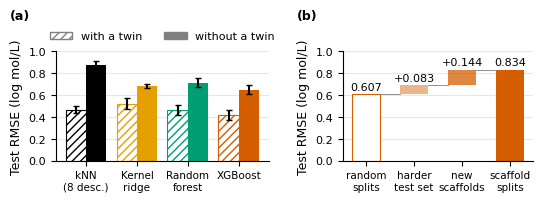

In [27]:
# Source: new figure (Figure 2 of the paper). (a) the descriptor-twin bar chart of 03_models.ipynb (section 6),
#         drawn again from its saved table. (b) new: a step chart of XGBoost's RMSE from Table 1, in which each bar
#         starts where the one before ends (bottom=). Bars as in Tutorial 4 (11.4)
# Changes: both panels in one figure, with panel letters as in the other paper figures
from matplotlib.patches import Patch   # legend entries drawn by hand, as in notebook 03

twins = pd.read_csv(os.path.join(TABLE_DIR, 'models_twins.csv'))   # saved by notebook 03
twin_mean = twins.groupby('model')[['rmse_twins', 'rmse_no_twin']].mean()
twin_sd = twins.groupby('model')[['rmse_twins', 'rmse_no_twin']].std()   # standard deviation over the 10 splits
bar_models = ['kNN (8 descriptors)', 'Kernel ridge', 'Random forest', 'XGBoost']   # as in notebook 03

# drawn at its printed size (5.5 in wide in the paper), so the text prints at the sizes set in src/esol_evaluation.py
fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(5.5, 1.92), gridspec_kw={'width_ratios': [1.12, 1]})

# (a) test RMSE with and without a descriptor twin (hatched: with a twin, filled: without)
for i, model_name in enumerate(bar_models):
    colour = MODEL_COLOURS[model_name]
    ax_a.bar(i - 0.2, twin_mean.loc[model_name, 'rmse_twins'], width=0.4, facecolor='white', edgecolor=colour,
             hatch='////', lw=0.8, yerr=twin_sd.loc[model_name, 'rmse_twins'], capsize=2)
    ax_a.bar(i + 0.2, twin_mean.loc[model_name, 'rmse_no_twin'], width=0.4, color=colour,
             yerr=twin_sd.loc[model_name, 'rmse_no_twin'], capsize=2)
ax_a.set_xticks(range(len(bar_models)))
ax_a.set_xticklabels(['kNN\n(8 desc.)', 'Kernel\nridge', 'Random\nforest', 'XGBoost'])
ax_a.set_ylabel('Test RMSE (log mol/L)')
ax_a.legend(handles=[Patch(facecolor='white', edgecolor='grey', hatch='////', label='with a twin'),
                     Patch(color='grey', label='without a twin')], frameon=False,
            loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=2)   # above the plot, grey stands for all models

# (b) XGBoost's mean test RMSE in two steps: a harder test set ("other ring" molecules of the random splits),
#     then new scaffolds (the scaffold splits). Numbers from Table 1 (section 6.1)
xgb = rmse_means.loc['XGBoost']
start, harder, end = xgb['random'], xgb['random, other ring'], xgb['scaffold']
colour = MODEL_COLOURS['XGBoost']
ax_b.bar(0, start, 0.6, facecolor='white', edgecolor=colour, lw=0.8)
ax_b.bar(1, harder - start, 0.6, bottom=start, color=colour, alpha=0.45)
ax_b.bar(2, end - harder, 0.6, bottom=harder, color=colour, alpha=0.75)
ax_b.bar(3, end, 0.6, color=colour)
for x, top, label in [(0, start, f'{start:.3f}'), (1, harder, f'+{harder - start:.3f}'),
                      (2, end, f'+{end - harder:.3f}'), (3, end, f'{end:.3f}')]:
    ax_b.text(x, top + 0.02, label, ha='center', va='bottom', fontsize=8)
for x, level in [(0, start), (1, harder), (2, end)]:   # thin lines carry each level to the next bar
    ax_b.plot([x + 0.3, x + 0.7], [level, level], color='grey', lw=0.6)
ax_b.set_xticks(range(4))
ax_b.set_xticklabels(['random\nsplits', 'harder\ntest set', 'new\nscaffolds', 'scaffold\nsplits'])
ax_b.set_ylabel('Test RMSE (log mol/L)')   # the caption says the panel shows XGBoost

for ax in (ax_a, ax_b):
    ax.set_ylim(0, 1.0)   # the same scale in both panels
    ax.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
    ax.tick_params(axis='x', labelsize=7.5)   # the four names under each panel need the room
    ax.grid(True, axis='y', alpha=0.3)
    ax.set_axisbelow(True)   # grid lines behind the bars
plt.tight_layout()
# each panel letter above the left end of its panel, found after tight_layout (as for Figure 4 in notebook 05).
# get_tightbbox gives the box around a panel and its labels in pixels, and transformed(...) turns it into
# figure coordinates (0 to 1), the units fig.text uses
renderer = fig.canvas.get_renderer()
for ax, letter in [(ax_a, '(a)'), (ax_b, '(b)')]:
    left = ax.get_tightbbox(renderer).transformed(fig.transFigure.inverted()).x0
    fig.text(left, 0.97, letter, fontweight='bold')
fig.savefig(os.path.join(FIG_DIR, 'scaffold_twins_and_steps.png'), bbox_inches='tight')
# a PDF copy stays sharp when the paper is zoomed in (no creation date, so every run gives the same file)
fig.savefig(os.path.join(FIG_DIR, 'scaffold_twins_and_steps.pdf'), bbox_inches='tight',
            metadata={'CreationDate': None})
plt.show()

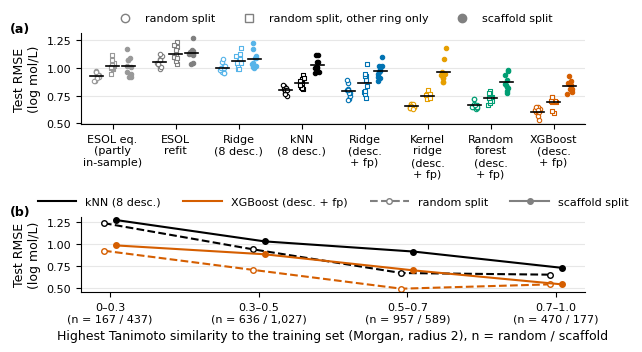

In [28]:
# Source: new figure. Scatter plot as in Tutorial 1 (6.) and line plot as in Tutorial 4 (12.3)
# Changes: colours per model from src/esol_evaluation.py, ridge with fingerprints in a darker blue
fig, (ax_a, ax_b) = plt.subplots(2, 1, figsize=(FULL_WIDTH, 3.6), height_ratios=[1.2, 1])   # the size in the paper

# (a) test RMSE of each model on the three test sets of section 6.1 (one dot per split, line = mean)
plot_models = ['ESOL equation (Delaney, 2004)', 'ESOL refit (Crippen logP)', 'Ridge (8 descriptors)',
               'kNN (8 descriptors)', 'Ridge (descriptors + fingerprints)', 'Kernel ridge', 'Random forest', 'XGBoost']
short_names = ['ESOL eq.\n(partly\nin-sample)', 'ESOL\nrefit', 'Ridge\n(8 desc.)', 'kNN\n(8 desc.)',
               'Ridge\n(desc.\n+ fp)',
               'Kernel\nridge\n(desc.\n+ fp)', 'Random\nforest\n(desc.\n+ fp)', 'XGBoost\n(desc.\n+ fp)']
colours = MODEL_COLOURS
markers = {'random': 'o', 'random, other ring': 's', 'scaffold': 'o'}
rng = np.random.default_rng(RANDOM_SEED)   # as in Tutorial 4 (4.1), small shift so the dots do not hide each other
for i, model_name in enumerate(plot_models):
    colour = colours[model_name]
    for shift, test_set in [(-0.25, 'random'), (0, 'random, other ring'), (0.25, 'scaffold')]:
        values = np.array(split_rmse[(model_name, test_set)])
        face = colour if test_set == 'scaffold' else 'white'
        ax_a.scatter(i + shift + rng.uniform(-0.04, 0.04, len(values)), values, s=10, marker=markers[test_set],
                     facecolor=face, edgecolor=colour, lw=0.8)
        ax_a.plot([i + shift - 0.1, i + shift + 0.1], [values.mean(), values.mean()], color='k', lw=1.2)
# axes, labels and legend of (a)
ax_a.set_xticks(range(len(plot_models)))
ax_a.set_xticklabels(short_names, fontsize=8)
ax_a.set_xlim(-0.5, len(plot_models) - 0.5)
ax_a.set_ylabel('Test RMSE\n(log mol/L)')   # two lines, as in (b), so the label ends below the panel letter
ax_a.grid(True, axis='y', alpha=0.3)
ax_a.set_axisbelow(True)
ax_a.legend(handles=[Line2D([], [], marker='o', ls='', mfc='white', mec='grey', label='random split'),
                     Line2D([], [], marker='s', ls='', mfc='white', mec='grey', label='random split, other ring only'),
                     Line2D([], [], marker='o', ls='', mfc='grey', mec='grey', label='scaffold split')],
            frameon=False, loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=3)
ax_a.text(-0.1, 1.02, '(a)', transform=ax_a.transAxes, fontweight='bold', ha='right')   # left of the axis label

# (b) RMSE against the similarity to the training set (all 10 splits pooled), n = molecules per bin
x = np.arange(len(SIMILARITY_LABELS))
# tick labels with the number of molecules in each bin
tick_labels = []
for k, label in enumerate(SIMILARITY_LABELS):
    rows = by_similarity[(by_similarity['model'] == 'XGBoost') & (by_similarity['similarity_bin'] == label)]
    n_random = rows[rows['split'] == 'random']['n_molecules'].iloc[0]
    n_scaffold = rows[rows['split'] == 'scaffold']['n_molecules'].iloc[0]
    tick_labels.append(f'{label}\n(n = {n_random:,} / {n_scaffold:,})')
# kNN and XGBoost, dashed line for the random splits and solid line for the scaffold splits
for model_name, label in [('kNN (8 descriptors)', 'kNN (8 desc.)'), ('XGBoost', 'XGBoost (desc. + fp)')]:
    for split_type, style, face, shift in [('random', '--', 'white', -0.04),
                                           ('scaffold', '-', colours[model_name], 0.04)]:
        rows = by_similarity[(by_similarity['model'] == model_name) & (by_similarity['split'] == split_type)]
        ax_b.plot(x + shift, rows['rmse'], ls=style, marker='o', ms=4, color=colours[model_name], mfc=face)
ax_b.set_xticks(x)
ax_b.set_xticklabels(tick_labels, fontsize=8)
ax_b.set_xlabel('Highest Tanimoto similarity to the training set (Morgan, radius 2), n = random / scaffold')
ax_b.set_ylabel('Test RMSE\n(log mol/L)')
ax_b.set_yticks([0.5, 0.75, 1.0, 1.25])   # the same steps as in (a)
ax_b.grid(True, axis='y', alpha=0.3)
ax_b.set_axisbelow(True)
# one row of legend: the colour gives the model, the line style gives the kind of split
ax_b.legend(handles=[Line2D([], [], color=colours['kNN (8 descriptors)'], label='kNN (8 desc.)'),
                     Line2D([], [], color=colours['XGBoost'], label='XGBoost (desc. + fp)'),
                     Line2D([], [], color='grey', ls='--', marker='o', ms=4, mfc='white', label='random split'),
                     Line2D([], [], color='grey', ls='-', marker='o', ms=4, label='scaffold split')],
            frameon=False, fontsize=8, loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=4,
            handlelength=3.5)   # above the panel, with samples long enough to show the dashes
ax_b.text(-0.1, 1.02, '(b)', transform=ax_b.transAxes, fontweight='bold', ha='right')

plt.tight_layout()
fig.align_ylabels([ax_a, ax_b])   # the two y-labels in one column
fig.savefig(os.path.join(FIG_DIR, 'scaffold_random_vs_scaffold.png'), bbox_inches='tight')
# a PDF copy stays sharp when the paper is zoomed in (no creation date, so every run gives the same file)
fig.savefig(os.path.join(FIG_DIR, 'scaffold_random_vs_scaffold.pdf'), bbox_inches='tight',
            metadata={'CreationDate': None})
plt.show()

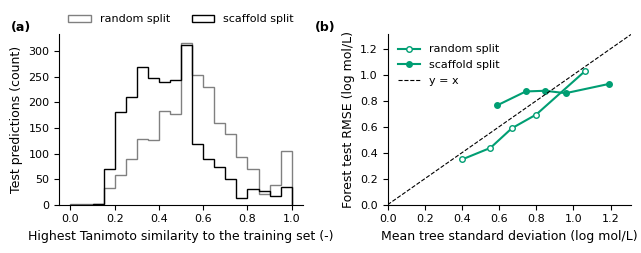

In [29]:
# Source: new figures for the appendix. Histogram as in Tutorial 3 (6. Data Visualization)
fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(FULL_WIDTH, 2.6))

# (a) how similar the test molecules are to the training set
for split_type, colour in [('random', 'grey'), ('scaffold', 'k')]:
    values = test_info[test_info['split'] == split_type]['max_similarity']
    ax_a.hist(values, bins=np.linspace(0, 1, 21), histtype='step', color=colour, lw=1.2, label=f'{split_type} split')
ax_a.set_xlabel('Highest Tanimoto similarity to the training set (-)')
ax_a.set_ylabel('Test predictions (count)')   # pooled over the 10 splits, a molecule can be in several
ax_a.legend(frameon=False, loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=2)
ax_a.text(-0.2, 1.02, '(a)', transform=ax_a.transAxes, fontweight='bold')

# (b) RMSE of each uncertainty group against its mean tree standard deviation
for split_type, face in [('random', 'white'), ('scaffold', MODEL_COLOURS['Random forest'])]:
    rows = uncertainty_groups.loc[split_type]
    ax_b.plot(rows['mean_tree_sd'], rows['rmse'], marker='o', ms=4, color=MODEL_COLOURS['Random forest'],
              mfc=face, label=f'{split_type} split')
# dashed y = x line: points on it have an RMSE equal to the mean tree standard deviation
limit = uncertainty_groups[['mean_tree_sd', 'rmse']].max().max() * 1.1
ax_b.plot([0, limit], [0, limit], 'k--', lw=0.8, label='y = x')
ax_b.set_xlim(0, limit)
ax_b.set_ylim(0, limit)
ax_b.set_xlabel('Mean tree standard deviation (log mol/L)')
ax_b.set_ylabel('Forest test RMSE (log mol/L)')
ax_b.legend(frameon=False, loc='upper left')
ax_b.text(-0.3, 1.02, '(b)', transform=ax_b.transAxes, fontweight='bold')

plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'uncertainty_similarity_and_groups.png'), bbox_inches='tight')
# a PDF copy stays sharp when the paper is zoomed in (no creation date, so every run gives the same file)
fig.savefig(os.path.join(FIG_DIR, 'uncertainty_similarity_and_groups.pdf'), bbox_inches='tight',
            metadata={'CreationDate': None})
plt.show()

random splits: 2230 predictions of 984 different molecules
scaffold splits: 2230 predictions of 548 different molecules


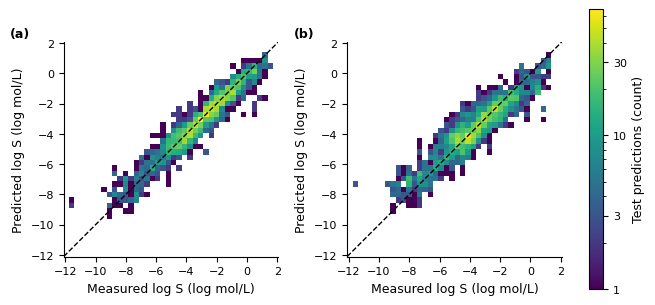

In [30]:
# Source: parity plot as a 2D histogram, hist_density() of Tutorial 4 (6.), XGBoost on all 10 test sets
# Changes: two panels with the same colour scale, (a) the random and (b) the scaffold splits. No panel titles.
#          The caption says which split each panel shows
xgb_rows = all_predictions[all_predictions['model'] == 'XGBoost']
limits = [xgb_rows[['y_true', 'y_pred']].min().min() - 0.5, xgb_rows[['y_true', 'y_pred']].max().max() + 0.5]
bins = np.linspace(limits[0], limits[1], 41)
# the largest count in any cell of either panel, so both panels use the same colours
largest = 0
for split_type, rows in xgb_rows.groupby('split'):
    cell_counts = np.histogram2d(rows['y_true'], rows['y_pred'], bins=[bins, bins])[0]
    largest = max(largest, cell_counts.max())
    print(f"{split_type} splits: {len(rows)} predictions of {rows['molecule'].nunique()} different molecules")

# constrained layout leaves room for one colour bar shared by both panels
fig, axes = plt.subplots(1, 2, figsize=(FULL_WIDTH, 3.0), layout='constrained')
for ax, split_type, label in [(axes[0], 'random', '(a)'), (axes[1], 'scaffold', '(b)')]:
    rows = xgb_rows[xgb_rows['split'] == split_type]
    h = ax.hist2d(rows['y_true'], rows['y_pred'], bins=[bins, bins], cmin=1, cmap='viridis',
                  norm=LogNorm(vmin=1, vmax=largest),   # as in hist_density(), Tutorial 4 (6.)
                  rasterized=True)   # the cells as one image in the PDF copy, so no thin lines between them
    ax.plot(limits, limits, 'k--', lw=1)   # perfect prediction
    ax.set_xlabel('Measured log S (log mol/L)')
    ax.set_ylabel('Predicted log S (log mol/L)')
    ax.set_xticks(np.arange(-12, 3, 2))
    ax.set_yticks(np.arange(-12, 3, 2))
    ax.set_aspect('equal')
    ax.text(-0.25, 1.02, label, transform=ax.transAxes, fontweight='bold')
colour_bar = fig.colorbar(h[3], ax=axes, label='Test predictions (count)')
colour_bar.set_ticks([1, 3, 10, 30])
colour_bar.set_ticklabels(['1', '3', '10', '30'])
fig.savefig(os.path.join(FIG_DIR, 'scaffold_parity_xgboost.png'), bbox_inches='tight')
# a PDF copy stays sharp when the paper is zoomed in (no creation date, so every run gives the same file)
fig.savefig(os.path.join(FIG_DIR, 'scaffold_parity_xgboost.pdf'), bbox_inches='tight',
            metadata={'CreationDate': None})
plt.show()

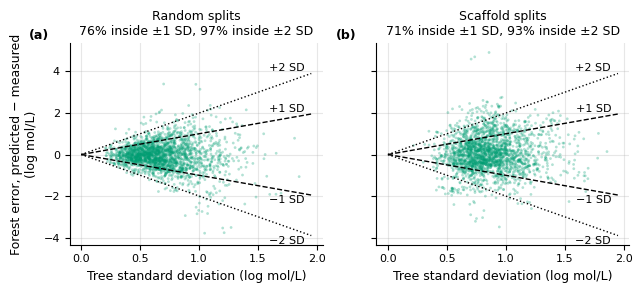

In [31]:
# Source: error against the predicted uncertainty as in Lecture 9 (slide 24), scatter plot as in Tutorial 1 (6.)
# Changes: lines at 1 and 2 tree SDs, and the share of test molecules inside them in the title
fig, axes = plt.subplots(1, 2, figsize=(FULL_WIDTH, 3.0), sharex=True, sharey=True)
sd_line = np.array([0, forest_rows['tree_sd'].max() * 1.05])
for ax, split_type, label in [(axes[0], 'random', '(a)'), (axes[1], 'scaffold', '(b)')]:
    rows = forest_rows[forest_rows['split'] == split_type]
    ax.scatter(rows['tree_sd'], rows['error'], s=4, alpha=0.3, color=MODEL_COLOURS['Random forest'], edgecolor='none')
    for k, style in [(1, '--'), (2, ':')]:
        ax.plot(sd_line, k * sd_line, color='k', ls=style, lw=1)
        ax.plot(sd_line, -k * sd_line, color='k', ls=style, lw=1)
        # labels just inside the end of each line
        ax.text(sd_line[1] * 0.97, k * sd_line[1], f'+{k} SD', ha='right', va='bottom', fontsize=8)
        ax.text(sd_line[1] * 0.97, -k * sd_line[1], f'\u2212{k} SD', ha='right', va='top', fontsize=8)
    within_1 = (rows['abs_error'] < rows['tree_sd']).mean()
    within_2 = (rows['abs_error'] < 2 * rows['tree_sd']).mean()
    ax.set_title(f'{split_type.capitalize()} splits\n'
                 f'{within_1:.0%} inside ±1 SD, {within_2:.0%} inside ±2 SD', fontsize=9)
    ax.set_xlabel('Tree standard deviation (log mol/L)')
    ax.grid(True, alpha=0.3)
    ax.set_axisbelow(True)
    ax.text(-0.16, 1.02, label, transform=ax.transAxes, fontweight='bold')
axes[0].set_ylabel('Forest error, predicted \u2212 measured\n(log mol/L)')
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'uncertainty_error_vs_tree_sd.png'), bbox_inches='tight')
plt.show()

**Observations (parity plot and error against uncertainty)**
- On the random splits most XGBoost predictions lie close to the diagonal, but the least soluble molecules are predicted too soluble. On the scaffold splits the predictions spread more around the diagonal, in line with the higher RMSE (0.83 against 0.61). The two panels do not show the same molecules. The scaffold test sets hold no substituted benzenes and no molecules without a ring, and most of their molecules appear in several of the 10 scaffold test sets (2,230 predictions of 548 different molecules, against 984 molecules on the random splits).
- On the random splits the errors of the forest fan out as the tree standard deviation grows, as in Lecture 9 (slide 24), although only moderately (Spearman 0.362, section 8). Of the errors, 76% lie inside one tree standard deviation and 97% inside two, against about 68% and 95% for normally distributed errors. On the scaffold splits the tree standard deviations are larger on average, so 71% and 93% of the errors still lie inside the lines, but the errors hardly widen with the tree standard deviation, which matches the weak correlation in section 8 (0.102). The size of the tree standard deviation is about right on average, but it does not show which of these molecules have the large errors.

## Next notebook

`05_interpretation.ipynb` looks at which descriptors the models rely on (permutation importance and SHAP, Lecture 8) and which families of molecules are predicted worst.